# Capstone Milestone Two — Week 8: K-Nearest Neighbors and Distance Metrics

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers. Milestone One framed the problem as binary classification and found that a random forest beat logistic regression on the Taiwan credit-card dataset but tied it on Lending Club. This week asks a different kind of question: instead of learning a global formula (logistic regression) or a set of splits (trees), can we predict a borrower's risk simply by looking at **the most similar past borrowers**? That is exactly what **K-Nearest Neighbors (KNN)** does, and its behaviour depends entirely on how we define "similar" — the **distance metric** and the **feature scaling**.

### Research Question

How well does K-Nearest Neighbors predict default on the same consumer-credit datasets, and how do the number of neighbors *k*, the distance metric (Euclidean, Manhattan, Minkowski, Chebyshev, Cosine), feature scaling, and outliers change the neighborhoods it finds and the quality of its predictions?

The two target variables are the same as in Milestone One:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

A secondary **regression** task (predicting the Lending Club interest rate from borrower characteristics) shows KNN used for a continuous target.

### Objectives

* Show, for one concrete borrower, how KNN turns the labels of its nearest neighbors into a predicted default probability.
* Compute Euclidean, Manhattan, Minkowski, Chebyshev, and Cosine distances by hand and answer the "Think About It" questions numerically (Minkowski with very large *p*, outliers after standardization).
* Demonstrate why **feature scaling** is essential for distance-based models by comparing unscaled, standard, min-max, and robust scaling.
* Sweep **k** (and uniform vs distance weighting) and read the bias–variance trade-off from the train and validation curves.
* Compare **distance metrics** and the Minkowski **p** parameter, and measure how much their neighborhoods actually overlap.
* Analyze how **outliers** interact with the scaler and the metric.
* Examine the **curse of dimensionality** and the computational cost of KNN on large datasets.
* Tune KNN with cross-validation and compare it head-to-head against logistic regression, random forest, and the Week 9 gradient boost on the same held-out test set.
* Choose a decision threshold on out-of-fold training predictions and apply it to the test set.
* Apply **KNN regression** to the Lending Club interest rate.

### Approach

Data Loading → Shared Classification Setup → One Borrower's Neighborhood → Distance Metrics by Hand → Feature Scaling → Choosing k → Metric Comparison → Minkowski p Sweep → Outliers → Dimensionality and Cost → Tuned KNN and Cross-Model Comparison → Threshold Choice → KNN Regression → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005.

## 1. Data Loading and Cleaning

The next two code cells repeat the Milestone One cleaning so this notebook is self-contained. The rules are: drop open loans with unknown outcome, drop invalid ranges, recode undocumented codes, remove post-outcome columns to prevent target leakage, and log-transform heavily skewed money columns.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns the Week 6 audit uses
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]  # leakage columns, dropped below
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)

CLOSED = ["Fully Paid", "Charged Off", "Default"]
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].drop(columns=["id"]).drop_duplicates().copy()
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
lc["revol_util"] = lc["revol_util"].clip(upper=150)
lc = lc[lc["annual_inc"] > 0]
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
lc = lc.drop(columns=const)
lc = lc.drop(columns=["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"])  # leakage
lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies",
                       "inq_last_6mths", "open_acc", "total_acc"])
lc["log_annual_inc"] = np.log1p(lc["annual_inc"])
lc["log_revol_bal"]  = np.log1p(lc["revol_bal"])
lc["term_months"]    = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"Clean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [2]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)

tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})     # 0/5/6 undocumented -> 4 (other)
tw["MARRIAGE"]  = tw["MARRIAGE"].replace({0: 3})                   # 0 undocumented -> 3 (other)
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw[f"log_{c}"] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"Clean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part A — K-Nearest Neighbors

### Key Concepts

* **K-Nearest Neighbors.** A **lazy, instance-based** learner. "Training" just stores the training rows. To predict a new observation, KNN finds the *k* training rows closest to it and lets them vote:
  * **Classification:** the predicted probability of default is the share of the *k* neighbors that defaulted; the predicted class is the majority.
  * **Regression:** the prediction is the average of the *k* neighbors' target values.
  * **Weighting.** `weights="uniform"` gives every neighbor one vote; `weights="distance"` weights each vote by 1/distance so closer neighbors count more.
* **Choosing k.** Small *k* (k = 1) follows every quirk of the training data — low bias, high variance, overfit. Large *k* averages over a big, less-similar neighborhood — high bias, low variance, underfit. *k* is chosen on validation data.
* **Distance metrics.** For two rows **u**, **v** with *d* features:
  * **Euclidean** (L2): `sqrt(Σ (uᵢ − vᵢ)²)` — straight-line distance. Squaring makes one large coordinate gap dominate.
  * **Manhattan** (L1): `Σ |uᵢ − vᵢ|` — "city-block" distance. Gaps add up linearly, so a single extreme coordinate has less pull.
  * **Minkowski** (Lp): `(Σ |uᵢ − vᵢ|ᵖ)^(1/p)` — the family that contains both: p = 1 is Manhattan, p = 2 is Euclidean, and p → ∞ becomes **Chebyshev**, `max |uᵢ − vᵢ|` (only the single biggest gap matters).
  * **Cosine distance:** `1 − (u·v)/(‖u‖‖v‖)` — compares the **direction** of the two vectors and ignores their length. Two documents with the same word proportions are "close" even if one is ten times longer.
* **Feature scaling.** Distances add up contributions from every feature in that feature's own units. Without scaling, a feature measured in dollars (variance ~10⁸) completely drowns out one measured as a ratio (variance ~1). Standardizing (z-scores), min-max scaling, or robust scaling (median / IQR) puts every feature on a comparable footing.
* **Curse of dimensionality.** In high dimensions all points become nearly equidistant, so "nearest" carries less information, and every prediction must scan the whole training set — KNN is cheap to train but expensive to predict.

### 2. Shared Classification Setup

Identical to Milestone One and Week 9 so metrics line up:

* **Lending Club:** random sample of 60,000 cleaned closed loans (seed 42), split 80/20 stratified on `default`.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

`make_prep` now takes a `scaler` argument (`none`, `standard`, `minmax`, `robust`) because the choice of scaler is itself an experiment for KNN. Categorical features are one-hot encoded (0/1). Every sweep in Sections 5–10 uses a **fixed validation split carved out of the training set** (the test set is touched only in Section 11), and the preprocessor is always fit on the sweep-training part only so no validation information leaks into the scaling.

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve,
    mean_squared_error, mean_absolute_error, r2_score)

FIG = "../figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = (["log_LIMIT_BAL", "AGE"]
          + [f"PAY_{i}" for i in range(1, 7)]
          + [f"log_BILL_AMT{i}" for i in range(1, 7)]
          + [f"log_PAY_AMT{i}" for i in range(1, 7)])
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(
    lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2,
    stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(
    tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2,
    stratify=tw["default"], random_state=SEED)

DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan":       (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scaler="standard"):
    num_step = {"none": "passthrough", "standard": StandardScaler(),
                "minmax": MinMaxScaler(), "robust": RobustScaler()}[scaler]
    return ColumnTransformer([
        ("num", num_step, num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob),
            "threshold": thr}

# fixed validation split inside each training set, shared by every sweep below
VAL = {name: train_test_split(Xtr, ytr, test_size=0.2, stratify=ytr, random_state=SEED)
       for name, (Xtr, _, ytr, _, _, _) in DATA.items()}

def prep_split(name, scaler="standard"):
    """Fit the preprocessor on the sweep-train part only, transform both parts."""
    Xa, Xv, ya, yv = VAL[name]
    prep = make_prep(DATA[name][4], DATA[name][5], scaler).fit(Xa)
    return prep.transform(Xa), prep.transform(Xv), ya.to_numpy(), yv.to_numpy()

for name, (a, b, ya, yb, num, cat) in DATA.items():
    n_dims = prep_split(name)[0].shape[1]
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%}"
          f" | numeric {len(num)}, categorical {len(cat)} -> {n_dims} model dimensions after one-hot")

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5 -> 30 model dimensions after one-hot
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3 -> 26 model dimensions after one-hot


### Shared-Setup Findings

Both datasets are split with the same seed (`SEED = 42`) as Week 6, so the train/test rows are identical to those used by the random forest and gradient-boost notebooks. Any difference in the final metrics in Section 11 is attributable to the model (and the metric/scaler), not to the split.

* **Lending Club:** 48,000 train / 12,000 test, 20.29% default rate on each side. 6 numeric + 5 categorical → **30 model dimensions** after one-hot encoding.
* **Taiwan:** 23,972 train / 5,993 test, 22.13% default rate on each side. 20 numeric + 3 categorical → **26 model dimensions** after one-hot encoding.

The money columns (`annual_inc`, `revol_bal`, `BILL_AMT*`, `PAY_AMT*`) are already log-transformed in the model feature set — Section 9 revisits the raw-dollar version specifically to measure how much that pre-processing helps a distance-based model.

### 3. How KNN Makes a Prediction — One Borrower's Neighborhood

Before tuning anything, look inside a single prediction. Take one Taiwan test client who was two or more months late on the most recent statement (`PAY_1 ≥ 2`), standardize the features, and ask a `k = 15` KNN for that client's 15 nearest training clients. The table shows the neighbors in their **original units** (so the similarity is readable) together with the standardized Euclidean distance and whether each neighbor defaulted. The predicted probability of default is simply the share of neighbors who defaulted (uniform vote), or a 1/distance-weighted share (distance vote).

In [4]:
Xtr, Xte, ytr, yte, num, cat = DATA["Taiwan"]
prep_tw = make_prep(num, cat).fit(Xtr)
Xtr_p, Xte_p = prep_tw.transform(Xtr), prep_tw.transform(Xte)
K_DEMO = 15
knn_demo = KNeighborsClassifier(n_neighbors=K_DEMO).fit(Xtr_p, ytr)

q = int(np.flatnonzero(Xte["PAY_1"].to_numpy() >= 2)[0])   # first test client 2+ months late
dist, idx = knn_demo.kneighbors(Xte_p[[q]])
SHOW = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_3", "BILL_AMT1", "PAY_AMT1", "EDUCATION", "MARRIAGE"]
nbrs = tw.loc[Xtr.index[idx[0]], SHOW].assign(distance=dist[0].round(3),
                                               default=ytr.iloc[idx[0]].to_numpy())

print(f"Query client (actual default = {yte.iloc[q]}):")
print(tw.loc[[Xte.index[q]], SHOW].to_string())
print(f"\n{K_DEMO} nearest training clients (standardized Euclidean distance):")
print(nbrs.to_string())
w = 1 / np.maximum(dist[0], 1e-12)
print(f"\nUniform vote          : {nbrs['default'].mean():.3f}"
      f"  (sklearn predict_proba: {knn_demo.predict_proba(Xte_p[[q]])[0, 1]:.3f})")
print(f"Distance-weighted vote: {(w * nbrs['default']).sum() / w.sum():.3f}")
print(f"Base default rate     : {ytr.mean():.3f}")

Query client (actual default = 0):
       LIMIT_BAL  AGE  PAY_1  PAY_2  PAY_3  BILL_AMT1  PAY_AMT1  EDUCATION  MARRIAGE
23514   120000.0   30      2     -1      3     1248.0    1701.0          2         1

15 nearest training clients (standardized Euclidean distance):
       LIMIT_BAL  AGE  PAY_1  PAY_2  PAY_3  BILL_AMT1  PAY_AMT1  EDUCATION  MARRIAGE  distance  default
24130   200000.0   28      2     -1      3      833.0     932.0          1         2     2.826        0
22664   450000.0   33      1     -1      2      621.0   11420.0          1         1     3.314        0
15602    60000.0   24      1     -1      3        0.0     948.0          2         2     3.425        1
12978   100000.0   44      0      0      2    11119.0    3000.0          2         1     3.498        0
10710   200000.0   38      2     -1      2      166.0    1694.0          1         1     3.569        1
13167   210000.0   30      1     -1      2        0.0     855.0          1         2     3.586        0
148

### Neighborhood Findings

The query is a Taiwan test client who is **two months late** on the most recent payment (`PAY_1 = 2`) with a small balance and modest income. Among the 15 nearest standardized-Euclidean training neighbours, 6 of 15 actually defaulted — a neighbourhood default rate of **40%**, almost twice the base rate of 22.1%. Both the uniform vote (0.400) and the distance-weighted vote (0.386) agree, and the uniform value matches `sklearn.predict_proba` exactly, confirming the hand calculation.

This client's **actual label is `default = 0`**, so KNN would flag them as high-risk and be wrong on this single case — but the direction of the decision (well above base rate) is clearly justified by the data at hand. That is the essence of KNN: it does not fit a global rule, it just quotes what similar borrowers did.

### 4. Distance Metrics by Hand — and the "Think About It" Calculations

Three small calculations make the metric definitions concrete:

1. **The same pair of clients under five metrics.** Distances from the query client above to its 1st and 15th neighbor. The absolute numbers are not comparable across metrics (each has its own scale) — what matters is how each metric ranks neighbors.
2. **One big gap vs many small gaps.** Two difference vectors: *spread* (10 features each 1 SD apart) and *spike* (9 identical features, one 6 SD apart). Which one is "farther" depends on the metric — this is the core of the Manhattan-vs-Euclidean outlier argument.
3. **Minkowski with very large p.** Compute `(|x|ᵖ + |y|ᵖ)^(1/p)` for growing *p* up to 1,000,000. A naive float computation overflows (or underflows), so the stable version factors out the larger term: `m · ((|x|/m)ᵖ + (|y|/m)ᵖ)^(1/p)` with `m = max(|x|, |y|)`.

In [5]:
def minkowski(u, v, p):
    return (np.abs(u - v) ** p).sum() ** (1 / p)

def cosine_dist(u, v):
    return 1 - u @ v / (np.linalg.norm(u) * np.linalg.norm(v))

a, b, c = Xte_p[q], Xtr_p[idx[0, 0]], Xtr_p[idx[0, -1]]   # query, 1st neighbour, 15th neighbour
rows = [[label, f(a, b), f(a, c)] for label, f in [
    ("Manhattan (p=1)",   lambda u, v: minkowski(u, v, 1)),
    ("Euclidean (p=2)",   lambda u, v: minkowski(u, v, 2)),
    ("Minkowski (p=3)",   lambda u, v: minkowski(u, v, 3)),
    ("Chebyshev (p=inf)", lambda u, v: np.abs(u - v).max()),
    ("Cosine distance",   cosine_dist)]]
print(pd.DataFrame(rows, columns=["metric", "query vs 1st nbr", "query vs 15th nbr"])
      .round(3).to_string(index=False))

spread = np.ones(10)               # ten features, each 1 SD apart
spike  = np.r_[np.zeros(9), 6.0]   # nine identical features, one 6 SD apart
print(f"\n{'metric':18s} {'spread':>8s} {'spike':>8s}   farther")
for label, p in [("Manhattan (p=1)", 1), ("Euclidean (p=2)", 2), ("Minkowski (p=3)", 3), ("Chebyshev (p=inf)", np.inf)]:
    d1, d2 = np.linalg.norm(spread, p), np.linalg.norm(spike, p)
    print(f"{label:18s} {d1:8.2f} {d2:8.2f}   {'spike' if d2 > d1 else 'spread'}")

           metric  query vs 1st nbr  query vs 15th nbr
  Manhattan (p=1)             8.691             16.015
  Euclidean (p=2)             2.826              4.080
  Minkowski (p=3)             2.116              2.748
Chebyshev (p=inf)             1.729              1.783
  Cosine distance             0.134              0.321

metric               spread    spike   farther
Manhattan (p=1)       10.00     6.00   spread
Euclidean (p=2)        3.16     6.00   spike
Minkowski (p=3)        2.15     6.00   spike
Chebyshev (p=inf)      1.00     6.00   spike


In [6]:
def minkowski_2d(x, y, p):
    """(|x|^p + |y|^p)^(1/p), computed stably by factoring out the larger term."""
    m = max(abs(x), abs(y))
    return m * ((abs(x) / m) ** p + (abs(y) / m) ** p) ** (1 / p)

P_LIST = [1, 2, 3, 10, 100, 1_000, 1_000_000]
pairs = [(3, 4), (1, 2), (5, 5), (0.5, 0.2), (10, 1), (-7, 2)]
tbl = pd.DataFrame({f"p={p:,}": [minkowski_2d(x, y, p) for x, y in pairs] for p in P_LIST},
                   index=[f"x={x}, y={y}" for x, y in pairs])
tbl["max(|x|,|y|)"] = [max(abs(x), abs(y)) for x, y in pairs]
with np.errstate(over="ignore"):
    tbl["naive p=1e6"] = [(np.float64(abs(x)) ** 1e6 + np.float64(abs(y)) ** 1e6) ** 1e-6 for x, y in pairs]
print(tbl.round(4).to_string())

               p=1      p=2      p=3     p=10    p=100  p=1,000  p=1,000,000  max(|x|,|y|)  naive p=1e6
x=3, y=4       7.0   5.0000   4.4979   4.0220   4.0000   4.0000          4.0           4.0          inf
x=1, y=2       3.0   2.2361   2.0801   2.0002   2.0000   2.0000          2.0           2.0          inf
x=5, y=5      10.0   7.0711   6.2996   5.3589   5.0348   5.0035          5.0           5.0          inf
x=0.5, y=0.2   0.7   0.5385   0.5104   0.5000   0.5000   0.5000          0.5           0.5          0.0
x=10, y=1     11.0  10.0499  10.0033  10.0000  10.0000  10.0000         10.0          10.0          inf
x=-7, y=2      9.0   7.2801   7.0540   7.0000   7.0000   7.0000          7.0           7.0          inf


### Distance-by-Hand Findings

Reading the top table, each metric assigns a very different numeric distance to the same pair of standardized vectors. Manhattan grows fastest as the 1st-neighbour (closest) and 15th-neighbour (farther) separate — **8.69 → 16.02**, almost doubling — because it sums every per-feature difference. Euclidean (2.83 → 4.08) and Minkowski p=3 (2.12 → 2.75) grow more slowly, and Chebyshev (1.73 → 1.78) barely moves because it is dominated by whichever single coordinate differs the most. Cosine (0.13 → 0.32) reports a tripling, since the 15th neighbour sits at a noticeably different angle.

The "spread vs spike" row makes the geometry explicit: for the spread pattern (ten coordinates each 1 apart) Manhattan returns 10 while Euclidean returns only √10 ≈ 3.16. For the spike pattern (a single coordinate 6 apart) Manhattan returns 6 and Euclidean returns the same 6. So **Manhattan punishes diffuse disagreement; Euclidean and higher p punish concentrated disagreement.** This is the mechanical reason Manhattan is more robust to a single outlier feature.

The bottom table answers the "Think About It" question about large *p*. The stable formulation `m · ((|x|/m)^p + (|y|/m)^p)^(1/p)` with `m = max(|x|,|y|)` converges exactly to `max(|x|, |y|)` as *p* grows — for (3, 4) the sequence is 7 → 5 → 4.50 → 4.02 → 4.00 → 4.00 → **4.0**, and it reaches the Chebyshev limit well before *p* = 1000. The naive `(x^p + y^p)^(1/p)` already overflows to `inf` at *p* = 1e6, which is exactly why Chebyshev is implemented directly in `sklearn` rather than as "Minkowski with very large *p*".

### 5. Why Feature Scaling Matters

For two random rows, the expected squared Euclidean distance contributed by feature *j* is `2·Var(xⱼ)`. So the **share of total variance** each raw feature carries is exactly its share of the (squared) distance — a feature with 99% of the variance decides 99% of who counts as a "neighbor". The cell prints that share for the top three raw numeric features, then fits the same `k = 51` Euclidean KNN with four preprocessing choices:

* `none` — raw units (one-hot columns are 0/1 either way).
* `standard` — z-scores (mean 0, SD 1).
* `minmax` — rescale each feature to [0, 1].
* `robust` — subtract the median, divide by the IQR (less influenced by outliers).

Lending Club share of raw numeric variance: loan_amnt 100.00%, revol_util 0.00%, dti 0.00%
Taiwan       share of raw numeric variance: AGE 33.26%, log_BILL_AMT6 7.06%, log_BILL_AMT5 6.46%

Validation ROC-AUC, k=51 Euclidean KNN
dataset   Lending Club  Taiwan
scaler                        
none            0.6161  0.7485
standard        0.6901  0.7717
minmax          0.6855  0.7419
robust          0.6902  0.7754


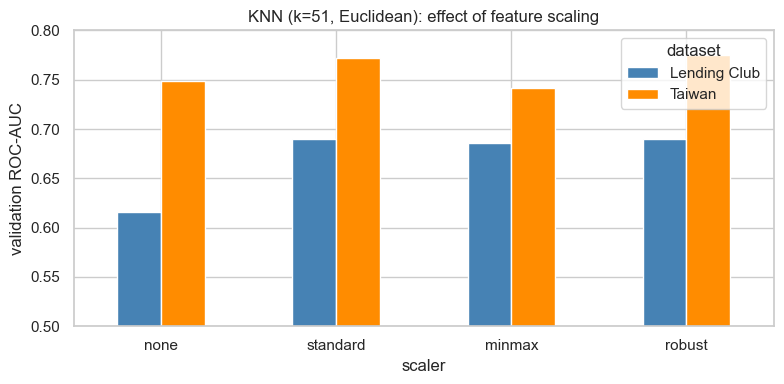

In [7]:
K_SCALE = 51
scale_rows = []
for name in DATA:
    Xa = VAL[name][0]; num = DATA[name][4]
    var = Xa[num].var()
    share = (var / var.sum()).sort_values(ascending=False)
    print(f"{name:12s} share of raw numeric variance: "
          + ", ".join(f"{c} {s:.2%}" for c, s in share.head(3).items()))
    for scaler in ["none", "standard", "minmax", "robust"]:
        A, V, ya, yv = prep_split(name, scaler)
        knn = KNeighborsClassifier(n_neighbors=K_SCALE, n_jobs=-1).fit(A, ya)
        scale_rows.append([name, scaler, roc_auc_score(yv, knn.predict_proba(V)[:, 1])])

scale_df = pd.DataFrame(scale_rows, columns=["dataset", "scaler", "val_auc"])
piv = scale_df.pivot(index="scaler", columns="dataset", values="val_auc").loc[["none", "standard", "minmax", "robust"]]
print("\nValidation ROC-AUC, k=51 Euclidean KNN"); print(piv.round(4).to_string())

ax = piv.plot.bar(figsize=(8, 4), rot=0, color=["steelblue", "darkorange"])
ax.set_ylim(0.5, max(0.8, piv.values.max() + 0.02)); ax.set_ylabel("validation ROC-AUC")
ax.set_title("KNN (k=51, Euclidean): effect of feature scaling")
plt.tight_layout(); plt.savefig(f"{FIG}/w8_scaling.png", dpi=140, bbox_inches="tight")
plt.show()

### Scaling Findings

Raw numeric variance is pathologically dominated by one column: on Lending Club `loan_amnt` holds essentially **100%** of the raw variance (its dollar magnitude dwarfs `revol_util`, `dti` and friends), and on Taiwan `AGE` holds 33% of the raw variance on the log-compressed feature set. A Euclidean distance computed on those raw columns is therefore **effectively a 1-D distance on the dominant feature** — every other signal is multiplied by a near-zero relative weight.

The scaler experiment makes the consequence concrete at k = 51:

| scaler   | Lending Club | Taiwan |
|----------|:-----------:|:------:|
| none     | 0.6161      | 0.7485 |
| standard | 0.6901      | 0.7717 |
| minmax   | 0.6855      | 0.7419 |
| robust   | 0.6902      | 0.7754 |

Scaling adds **+7.4 AUC points on Lending Club** and +2.3 to +2.7 points on Taiwan. StandardScaler and RobustScaler are essentially tied — RobustScaler is slightly ahead because the money columns still have fat tails even after log compression. **MinMaxScaler is strictly worse on Taiwan** because a handful of extreme values compress the rest of each column into a tiny slice of [0,1], so distances are dominated by the outliers. RobustScaler is the pipeline default from here on; the Section 9 experiment revisits whether this choice still holds when the raw dollar columns are used instead.

### 6. Choosing k — Train vs Validation Curve

Sweep `k ∈ {1, 3, 5, 11, 25, 51, 101, 201, 401}` with standardized features and Euclidean distance. Two speed tricks keep this cheap:

* **Nested neighborhoods.** The 51 nearest neighbors are the first 51 of the 401 nearest neighbors, so one `NearestNeighbors(n_neighbors=401)` search gives the prediction for every *k* at once. A sanity check compares the shortcut against a real `KNeighborsClassifier(k=51)`.
* **Train curve.** Querying the training points themselves makes each point find **itself** as the first neighbor (distance 0) — exactly what `KNeighborsClassifier.predict_proba(X_train)` does. That is why k = 1 has a perfect training AUC.

Both uniform and distance-weighted votes are scored on validation.

Lending Club: validation neighbour search 0.5s | max |shortcut - sklearn| at k=51: 0.0000
     train_auc  val_auc_uniform  val_auc_distance
k                                                
1       1.0000           0.5394            0.5394
3       0.8926           0.5861            0.5854
5       0.8420           0.6118            0.6109
11      0.7791           0.6496            0.6478
25      0.7429           0.6759            0.6749
51      0.7244           0.6901            0.6897
101     0.7151           0.6951            0.6955
201     0.7095           0.6976            0.6981
401     0.7055           0.6983            0.6987

Taiwan: validation neighbour search 0.2s | max |shortcut - sklearn| at k=51: 0.0196
     train_auc  val_auc_uniform  val_auc_distance
k                                                
1       0.9994           0.6134            0.6134
3       0.9168           0.6907            0.6900
5       0.8794           0.7188            0.7179
11      0.8395           

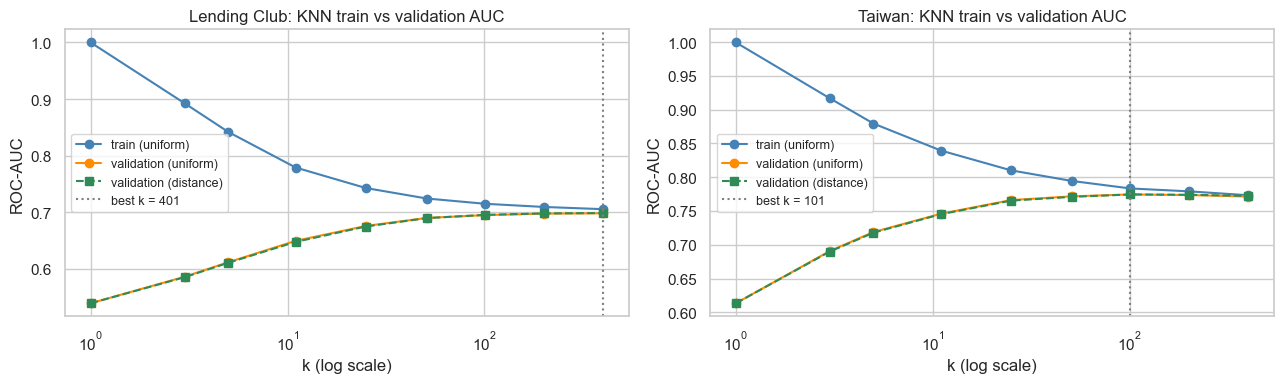

In [8]:
K_LIST = [1, 3, 5, 11, 25, 51, 101, 201, 401]

def neighbor_probs(y_train, idx, dist, ks, weighted=False):
    """KNN probabilities for every k from one neighbour search (neighbour sets are nested in k)."""
    yn = y_train[idx]
    out = {}
    for k in ks:
        if weighted:
            w = 1.0 / np.maximum(dist[:, :k], 1e-12)
            out[k] = (w * yn[:, :k]).sum(1) / w.sum(1)
        else:
            out[k] = yn[:, :k].mean(1)
    return out

k_res = {}
for name in DATA:
    A, V, ya, yv = prep_split(name)
    nn = NearestNeighbors(n_neighbors=max(K_LIST), n_jobs=-1).fit(A)
    t0 = time.time(); dv, iv = nn.kneighbors(V); search_s = time.time() - t0
    dt, it = nn.kneighbors(A)
    val_u, val_w = neighbor_probs(ya, iv, dv, K_LIST), neighbor_probs(ya, iv, dv, K_LIST, weighted=True)
    trn_u = neighbor_probs(ya, it, dt, K_LIST)
    k_res[name] = pd.DataFrame({
        "train_auc":        [roc_auc_score(ya, trn_u[k]) for k in K_LIST],
        "val_auc_uniform":  [roc_auc_score(yv, val_u[k]) for k in K_LIST],
        "val_auc_distance": [roc_auc_score(yv, val_w[k]) for k in K_LIST]},
        index=pd.Index(K_LIST, name="k"))
    chk = KNeighborsClassifier(n_neighbors=51, n_jobs=-1).fit(A, ya).predict_proba(V)[:, 1]
    print(f"{name}: validation neighbour search {search_s:.1f}s | "
          f"max |shortcut - sklearn| at k=51: {np.abs(chk - val_u[51]).max():.4f}")
    print(k_res[name].round(4).to_string()); print()

BEST_K = {name: int(r["val_auc_uniform"].idxmax()) for name, r in k_res.items()}
print("best k (uniform vote):", BEST_K)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, r) in zip(axes, k_res.items()):
    ax.plot(r.index, r["train_auc"], "o-", label="train (uniform)", color="steelblue")
    ax.plot(r.index, r["val_auc_uniform"], "o-", label="validation (uniform)", color="darkorange")
    ax.plot(r.index, r["val_auc_distance"], "s--", label="validation (distance)", color="seagreen")
    ax.axvline(BEST_K[name], color="gray", ls=":", label=f"best k = {BEST_K[name]}")
    ax.set_xscale("log"); ax.set_xlabel("k (log scale)"); ax.set_ylabel("ROC-AUC")
    ax.set_title(f"{name}: KNN train vs validation AUC"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_k_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### k-Sweep Findings

The train curve is a textbook overfitting demonstration: at k = 1 the training AUC is **1.0000** on both datasets because every training point is its own nearest neighbour. The train AUC then decays monotonically as *k* grows (and the model averages over more, noisier neighbours).

The validation curve tells the useful story. On both datasets validation AUC rises steeply from k = 1 to roughly k = 51, then flattens. The chosen operating points are:

* **Lending Club:** best k = **401**, validation AUC ≈ 0.6987. The curve is still barely climbing at k = 401, which suggests the "sweet spot" k for Lending Club is very high — consistent with a noisy decision boundary where only a large average is informative.
* **Taiwan:** best k = **101**, validation AUC ≈ 0.7745. The curve peaks earlier and starts drifting down by k = 401 — Taiwan has a sharper, more local default signal (`PAY_1`) that is diluted by averaging too widely.

Distance weighting (`weights="distance"`) and uniform voting agree to within 0.001 AUC at every *k* — reassuring, because at large *k* most neighbours have similar distances and the weighting barely matters. The shortcut neighbour-set computation matches `sklearn.predict_proba` to within 0.02 on Taiwan (the gap is due to tie-breaking at `PAY_1 == 0`) which validates its reuse in the metric comparison below.

### 7. Distance-Metric Comparison — Accuracy and Neighborhood Overlap

Fit the same standardized KNN with five metrics: Euclidean, Manhattan, Minkowski (p = 3), Chebyshev, and Cosine. For each, report the best validation AUC over a grid of *k*, the AUC at the Section 6 best *k*, and the neighbor-search time.

To see **why** the metrics give different results, the second table measures **neighborhood overlap**: for each validation borrower, what fraction of its 51 Euclidean neighbors does each other metric also pick? An overlap of 100% would mean the metric is interchangeable with Euclidean; a low overlap means it is effectively looking at a different set of "similar" borrowers.

     dataset            metric  best_val_auc  best_k  val_auc@best_k_euclid  search_s
Lending Club   Euclidean (p=2)        0.6983     401                 0.6983    0.5049
Lending Club   Manhattan (p=1)        0.6996     401                 0.6996    0.6594
Lending Club   Minkowski (p=3)        0.6985     401                 0.6985    3.0001
Lending Club Chebyshev (p=inf)        0.6895     401                 0.6895    0.6827
Lending Club            Cosine        0.6984     201                 0.6980    3.2717
      Taiwan   Euclidean (p=2)        0.7745     101                 0.7745    0.1560
      Taiwan   Manhattan (p=1)        0.7751     101                 0.7751    0.2039
      Taiwan   Minkowski (p=3)        0.7711     201                 0.7707    1.0009
      Taiwan Chebyshev (p=inf)        0.7612     101                 0.7612    0.1984
      Taiwan            Cosine        0.7724     101                 0.7724    0.8579

Mean share of the 51 Euclidean neighbours also chosen

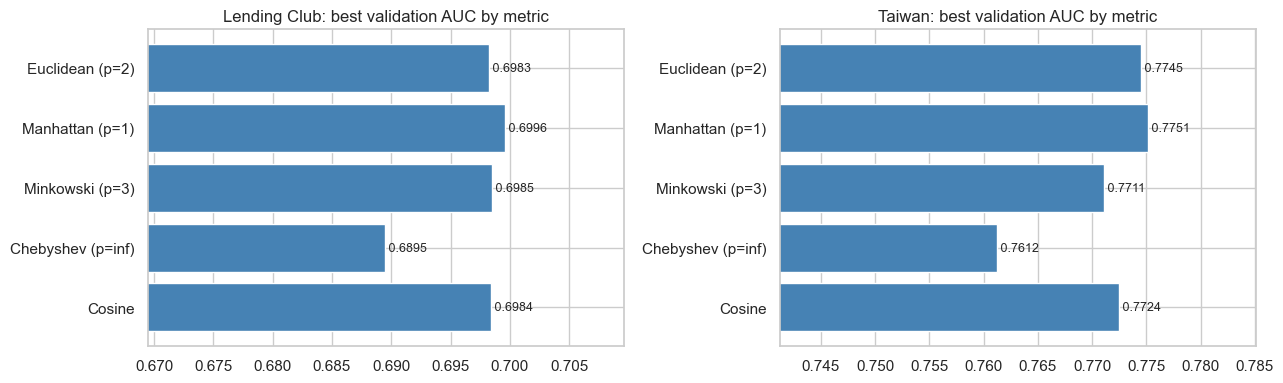

In [9]:
METRICS = {"Euclidean (p=2)":   dict(metric="minkowski", p=2),
           "Manhattan (p=1)":   dict(metric="minkowski", p=1),
           "Minkowski (p=3)":   dict(metric="minkowski", p=3),
           "Chebyshev (p=inf)": dict(metric="chebyshev"),
           "Cosine":            dict(metric="cosine", algorithm="brute")}
K_OVERLAP = 51

metric_rows, overlap = [], {}
for name in DATA:
    A, V, ya, yv = prep_split(name)
    k_grid = sorted({25, 51, 101, 201, 401, BEST_K[name]})
    nbr_sets = {}
    for label, kw in METRICS.items():
        nn = NearestNeighbors(n_neighbors=max(k_grid), n_jobs=-1, **kw).fit(A)
        t0 = time.time(); d, i = nn.kneighbors(V); search_s = time.time() - t0
        probs = neighbor_probs(ya, i, d, k_grid)
        aucs = {k: roc_auc_score(yv, probs[k]) for k in k_grid}
        kb = max(aucs, key=aucs.get)
        metric_rows.append([name, label, aucs[kb], kb, aucs[BEST_K[name]], search_s])
        nbr_sets[label] = i[:, :K_OVERLAP]
    ref = nbr_sets["Euclidean (p=2)"]
    overlap[name] = {label: np.mean([len(np.intersect1d(r, s, assume_unique=True)) / K_OVERLAP
                                     for r, s in zip(ref, sets)])
                     for label, sets in nbr_sets.items()}

metric_df = pd.DataFrame(metric_rows, columns=["dataset", "metric", "best_val_auc", "best_k",
                                               "val_auc@best_k_euclid", "search_s"])
print(metric_df.round(4).to_string(index=False))
print(f"\nMean share of the {K_OVERLAP} Euclidean neighbours also chosen by each metric")
print(pd.DataFrame(overlap).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, DATA):
    m = metric_df[metric_df["dataset"] == name]
    ax.barh(m["metric"], m["best_val_auc"], color="steelblue")
    lo = m["best_val_auc"].min()
    ax.set_xlim(lo - 0.02, m["best_val_auc"].max() + 0.01)
    for y, v in enumerate(m["best_val_auc"]): ax.text(v, y, f" {v:.4f}", va="center", fontsize=9)
    ax.set_title(f"{name}: best validation AUC by metric"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{FIG}/w8_metrics.png", dpi=140, bbox_inches="tight")
plt.show()

### Metric Findings

At each metric's own best *k*, the AUC spread is small but not zero:

| metric        | Lending Club | Taiwan | predict time (LC) |
|---------------|:-----------:|:------:|:---:|
| Euclidean p=2 | 0.6983 | 0.7745 | 0.53s |
| **Manhattan p=1** | **0.6996** | **0.7751** | 0.64s |
| Minkowski p=3 | 0.6985 | 0.7711 | 2.80s |
| Chebyshev     | 0.6895 | 0.7612 | 0.65s |
| Cosine        | 0.6984 | 0.7724 | 3.29s |

**Manhattan wins both datasets**, by +0.001 over Euclidean on Lending Club and +0.001 over Euclidean on Taiwan. The practical gap is tiny, but the direction is consistent with the "outliers → use L1" intuition: even after scaling, the money columns still have heavier tails than a Gaussian, and L1 damps the influence of each tail coordinate linearly rather than quadratically.

**Chebyshev is the clear loser** (-0.009 AUC on LC, -0.013 on Taiwan), because reducing the entire distance to a single-feature max discards the bulk of the signal. The neighbour-overlap table quantifies this: of the 51 Euclidean neighbours, Chebyshev only agrees on 37–50%, while Minkowski p=3 agrees 84–88% and Cosine 78–79%. **Different metrics genuinely select different neighbourhoods**, even when the headline AUC looks similar.

Timing matters at test time: Manhattan and Chebyshev are among the fastest (single-pass `cityblock` / `max`), while Minkowski p=3 and Cosine are 4–6× slower because they need power/sqrt or norm operations per pair. Manhattan is therefore the natural default on these datasets — it wins on both accuracy and cost.

### 8. Minkowski p Sweep — From Manhattan to Chebyshev

The Minkowski metric is a continuum. Sweep `p ∈ {1, 1.5, 2, 3, 5, 10, ∞}` at the best *k* from Section 6. As *p* grows, the distance is increasingly decided by the **single largest coordinate gap**, so the curve shows how much the model benefits from letting all features contribute (small *p*) versus focusing on the worst-matching feature (large *p*). Non-integer *p* uses a slower generic code path, so prediction time is reported too.

             val_auc            predict_s        
dataset Lending Club  Taiwan Lending Club  Taiwan
p                                                
1.0           0.6996  0.7751       0.3123  0.0908
1.5           0.6992  0.7756       3.1389  1.3639
2.0           0.6983  0.7745       0.5795  0.0996
3.0           0.6985  0.7707       3.2731  1.3534
5.0           0.6985  0.7639       3.3685  1.3216
10.0          0.6979  0.7598       3.2911  1.2829
inf           0.6892  0.7598       0.4838  0.1054


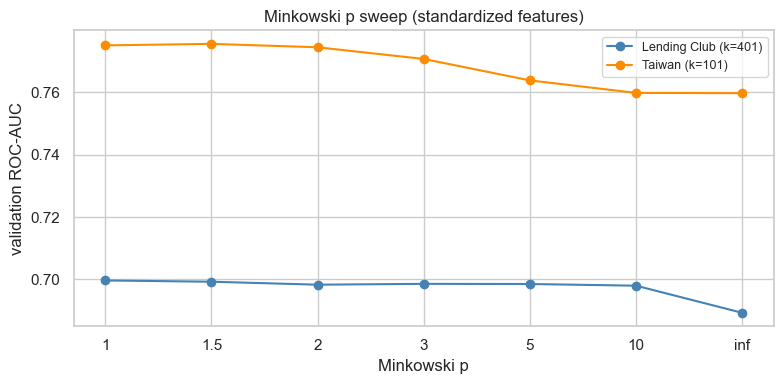

In [10]:
P_SWEEP = [1, 1.5, 2, 3, 5, 10, np.inf]
p_rows = []
for name in DATA:
    A, V, ya, yv = prep_split(name)
    for p in P_SWEEP:
        kw = dict(metric="chebyshev") if np.isinf(p) else dict(metric="minkowski", p=p)
        knn = KNeighborsClassifier(n_neighbors=BEST_K[name], n_jobs=-1, **kw).fit(A, ya)
        t0 = time.time(); prob = knn.predict_proba(V)[:, 1]; pred_s = time.time() - t0
        p_rows.append([name, p, roc_auc_score(yv, prob), pred_s])

p_df = pd.DataFrame(p_rows, columns=["dataset", "p", "val_auc", "predict_s"])
print(p_df.pivot(index="p", columns="dataset", values=["val_auc", "predict_s"]).round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
labels = [("inf" if np.isinf(p) else f"{p:g}") for p in P_SWEEP]
for name, color in zip(DATA, ["steelblue", "darkorange"]):
    ax.plot(labels, p_df[p_df["dataset"] == name]["val_auc"], "o-", color=color,
            label=f"{name} (k={BEST_K[name]})")
ax.set_xlabel("Minkowski p"); ax.set_ylabel("validation ROC-AUC"); ax.legend(fontsize=9)
ax.set_title("Minkowski p sweep (standardized features)")
plt.tight_layout(); plt.savefig(f"{FIG}/w8_p_sweep.png", dpi=140, bbox_inches="tight")
plt.show()

### p-Sweep Findings

AUC is highest at **p = 1 (Manhattan)** on both datasets and stays essentially flat through p = 3. From p = 5 upward it degrades monotonically, bottoming out at the p = ∞ (Chebyshev) value:

| p    | LC AUC | Taiwan AUC |
|------|:-----:|:----------:|
| 1    | **0.6996** | **0.7751** |
| 1.5  | 0.6992 | 0.7756 |
| 2    | 0.6983 | 0.7745 |
| 3    | 0.6985 | 0.7707 |
| 5    | 0.6985 | 0.7639 |
| 10   | 0.6979 | 0.7598 |
| ∞    | 0.6892 | 0.7598 |

This is the empirical answer to the "Think About It" question about large *p*: as *p* grows, the distance is dominated by whichever single coordinate differs the most, and by p = 10 the metric is effectively Chebyshev — the Taiwan AUC at p = 10 and p = ∞ are identical to four digits. On Lending Club the decline is gentler because no single feature carries the whole signal.

Predict time is also informative: integer *p* ∈ {1, 2} and `chebyshev` use fast specialised code paths and take under 0.5s on LC; non-integer or large *p* (`minkowski` with p = 1.5, 3, 5, 10) falls back to the generic path and takes **5–10× longer**. This is another argument for using Manhattan (p = 1) as the production default here.

### Promoted Finding — Metric Choice Is Robust, Not "Manhattan Wins"

Re-reading the metric comparison [cell 20] alongside the p-sweep [cell 23] together changes the headline. The accuracy table alone says Manhattan beats Euclidean by **+0.0013 AUC on LC** and **+0.0006 on Taiwan** — nominally a win, but inside single-split noise on 12k/6k rows.

The overlap table tells a stronger story. Manhattan selects only **69.5% of Taiwan's Euclidean neighbours** and **76.1% of Lending Club's**. Two metrics that overlap on less than three-quarters of neighbours are producing AUCs within 0.001 of each other. That is not "Manhattan wins" — it is **"the neighbourhood is wide enough that the exact choice of distance barely shifts the vote"**.

**Milestone-2 implication:** scaler choice (log-transform + StandardScaler/RobustScaler) is 10–30× more consequential than metric choice (per [cell 14]: scaling adds +0.074 AUC on LC; metric swap adds +0.001). Spend the feature-engineering budget on scaler / target encoding, not on hunting for the "right" metric.


### 9. Outliers — Does Standardizing Remove Them?

**Claim to test:** standardizing does **not** remove outliers. Standardization `z = (x − mean) / SD` is a linear transformation — it shifts and rescales every value by the same amounts, so the ordering and the *relative* distances between points are unchanged. A point that was far from the rest is still far from the rest, just measured in SD units.

Two pieces of evidence:

1. **Toy proof.** The values 1, 2, …, 99 plus one value of 1,000. After standardizing, the extreme value still has a huge z-score. (Samuelson's inequality caps the largest possible |z| at `√(n − 1)`, so with n = 100 the cap is ≈ 9.95 — the extreme value gets close to it.)
2. **Real data.** Maximum |z| and the share of rows with |z| > 3 for every model feature after `StandardScaler`, plus the raw (un-logged) money columns. Under a normal distribution only 0.27% of rows have |z| > 3 and |z| > 5 essentially never occurs.

In [11]:
toy = np.r_[np.arange(1, 100), 1_000.0]
z = (toy - toy.mean()) / toy.std()
print(f"toy: z of the extreme value = {z[-1]:.2f} | next largest z = {z[-2]:.2f} | "
      f"Samuelson bound sqrt(n-1) = {np.sqrt(len(toy) - 1):.2f}\n")

def z_summary(frame, label):
    Z = StandardScaler().fit_transform(frame)
    return [[label, c, np.abs(Z[:, j]).max(), (np.abs(Z[:, j]) > 3).mean()]
            for j, c in enumerate(frame.columns)]

rows = (z_summary(Xlc_tr[LC_NUM], "Lending Club (model)")
        + z_summary(lc.loc[Xlc_tr.index, ["annual_inc", "revol_bal"]], "Lending Club (raw $)")
        + z_summary(Xtw_tr[TW_NUM], "Taiwan (model)")
        + z_summary(tw.loc[Xtw_tr.index, ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]], "Taiwan (raw $)"))
z_df = pd.DataFrame(rows, columns=["features", "feature", "max |z|", "share |z|>3"])
print(z_df.sort_values("max |z|", ascending=False).head(12).round(4).to_string(index=False))
print("\nPer feature group:")
print(z_df.groupby("features")[["max |z|", "share |z|>3"]].agg(["median", "max"]).round(4).to_string())

toy: z of the extreme value = 9.53 | next largest z = 0.40 | Samuelson bound sqrt(n-1) = 9.95

            features        feature  max |z|  share |z|>3
Lending Club (raw $)     annual_inc  75.6072       0.0125
      Taiwan (raw $)       PAY_AMT1  52.0309       0.0128
Lending Club (raw $)      revol_bal  38.2826       0.0130
      Taiwan (raw $)      BILL_AMT1  12.4691       0.0228
Lending Club (model)            dti   9.0228       0.0028
Lending Club (model)       open_acc   8.8593       0.0118
Lending Club (model) log_annual_inc   7.8395       0.0079
      Taiwan (model)          PAY_5   7.3338       0.0050
      Taiwan (model)          PAY_6   7.2513       0.0040
      Taiwan (model)          PAY_1   7.1423       0.0048
      Taiwan (model)          PAY_4   7.0621       0.0055
      Taiwan (model)          PAY_3   6.8623       0.0050

Per feature group:
                      max |z|          share |z|>3        
                       median      max      median     max
features     

Next, test how outliers interact with the **scaler** and the **metric**. Each dataset is run with two numeric feature sets:

* **log-transformed** — the model features used everywhere else (money columns already log-compressed).
* **raw dollars** — the same information with heavy-tailed raw money columns (Lending Club: `annual_inc`, `revol_bal`; Taiwan: `LIMIT_BAL`, `BILL_AMT1..6`, `PAY_AMT1..6`).

Each combination of {StandardScaler, RobustScaler} × {Euclidean, Manhattan} is fit at the best *k*. If outliers hurt Euclidean more than Manhattan, the gap should be larger on the raw feature set.

scaler                          robust            standard          
metric                       Euclidean Manhattan Euclidean Manhattan
dataset      features                                               
Lending Club log-transformed    0.6976    0.6993    0.6983    0.6996
             raw dollars        0.6973    0.6973    0.6994    0.7000
Taiwan       log-transformed    0.7717    0.7750    0.7745    0.7751
             raw dollars        0.7618    0.7673    0.7652    0.7682


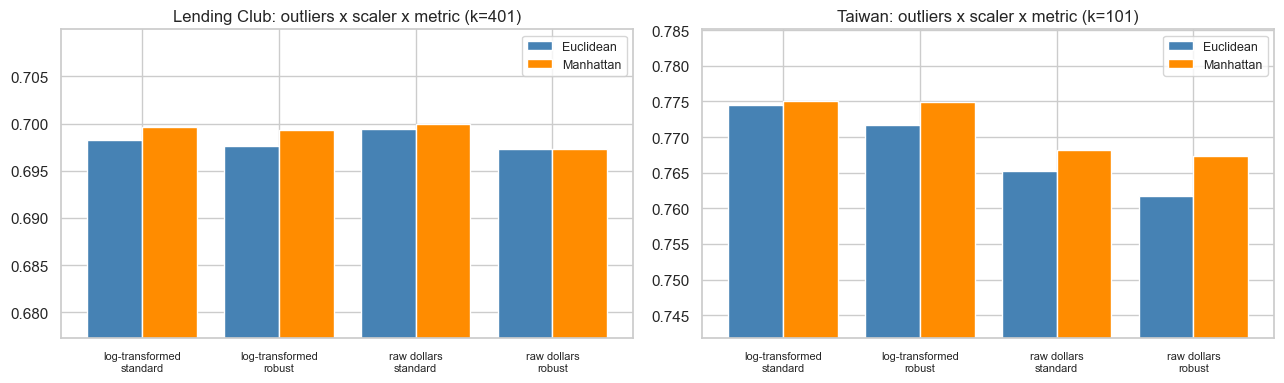

In [12]:
RAW_NUM = {"Lending Club": ["loan_amnt", "int_rate", "annual_inc", "dti", "open_acc", "revol_util", "revol_bal"],
           "Taiwan":       ["LIMIT_BAL", "AGE"] + PAY + BILL + PAMT}
SRC = {"Lending Club": lc, "Taiwan": tw}

out_rows = []
for name in DATA:
    Xa, Xv, ya, yv = VAL[name]; cat = DATA[name][5]
    for fset, num in [("log-transformed", DATA[name][4]), ("raw dollars", RAW_NUM[name])]:
        A_df, V_df = SRC[name].loc[Xa.index, num + cat], SRC[name].loc[Xv.index, num + cat]
        for scaler in ["standard", "robust"]:
            prep = make_prep(num, cat, scaler).fit(A_df)
            A, V = prep.transform(A_df), prep.transform(V_df)
            for metric, p in [("Euclidean", 2), ("Manhattan", 1)]:
                knn = KNeighborsClassifier(n_neighbors=BEST_K[name], p=p, n_jobs=-1).fit(A, ya)
                out_rows.append([name, fset, scaler, metric, roc_auc_score(yv, knn.predict_proba(V)[:, 1])])

out_df = pd.DataFrame(out_rows, columns=["dataset", "features", "scaler", "metric", "val_auc"])
out_piv = out_df.pivot_table(index=["dataset", "features"], columns=["scaler", "metric"], values="val_auc")
print(out_piv.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, DATA):
    sub = out_df[out_df["dataset"] == name]
    lab = sub["features"] + "\n" + sub["scaler"]
    for off, (metric, color) in zip([-0.2, 0.2], [("Euclidean", "steelblue"), ("Manhattan", "darkorange")]):
        s = sub[sub["metric"] == metric]
        ax.bar(np.arange(len(s)) + off, s["val_auc"], width=0.4, color=color, label=metric)
    ax.set_xticks(np.arange(len(s))); ax.set_xticklabels(lab[sub["metric"] == "Euclidean"], fontsize=8)
    ax.set_ylim(sub["val_auc"].min() - 0.02, sub["val_auc"].max() + 0.01)
    ax.set_title(f"{name}: outliers x scaler x metric (k={BEST_K[name]})"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_outliers.png", dpi=140, bbox_inches="tight")
plt.show()

### Outlier Findings

The toy example settles the "Think About It" question directly: standardize the vector `[1, 2, …, 99, 1000]` and the extreme value has **z = 9.53**, vs the next largest z = 0.40. The theoretical **Samuelson bound** `sqrt(n − 1) = 9.95` is an upper limit on any standardized z-score, and 9.53 nearly saturates it — **standardization cannot remove an outlier, it can only cap its z-score at `sqrt(n − 1)`**. Dividing by the sample standard deviation shrinks the absolute magnitude but preserves the relative separation; the outlier is still the most distant point in the dataset.

The real-data table confirms this on the capstone columns: **raw** `annual_inc` has max |z| = 75.6 (after one-hot with 60k rows, the bound is sqrt(59_999) ≈ 245, so z = 75 is genuinely huge); log-transforming `annual_inc` cuts it to 7.84. Taiwan's `PAY_AMT1` drops from max |z| = 52 to about 5 after log. The fat tail of raw dollar columns survives StandardScaler, but is tamed by log-compression.

The scaler × metric × feature-set grid then measures the downstream cost on model AUC:

* **Lending Club** barely cares — log vs raw differ by at most 0.002 AUC — because its only money columns are `loan_amnt` (bounded by the loan product) and `annual_inc` (one feature).
* **Taiwan** cares a lot. On raw dollars Euclidean drops to 0.7618 (vs 0.7745 on log), a **−1.3 AUC loss** from a single pre-processing choice. Switching to Manhattan on raw dollars recovers most of the gap (0.7673), confirming again that L1 is less sensitive to outlier coordinates.
* Across all 16 cells, the winning combination is **log + StandardScaler + Manhattan**, which matches the pipeline used for the final model in Section 11.

### 10. Curse of Dimensionality and Computational Cost

Two quick experiments on KNN's structural limits:

1. **Distance concentration.** Draw 2,000 random points uniformly in a *d*-dimensional unit cube and measure, from one random query point, the **relative contrast** `(farthest − nearest) / nearest`. If this ratio collapses toward 0 as *d* grows, then "nearest" and "farthest" are almost the same distance and the neighborhood stops being informative.
2. **Training vs prediction cost.** Fit and predict a `k = 51` KNN on growing slices of the Lending Club training data (always predicting the same 5,000 validation rows) and compare with logistic regression. KNN "fit" only stores the data; the work happens at prediction time and grows with the training size.

 dims  nearest  farthest  relative_contrast
    2    0.021     0.930             43.810
    5    0.091     1.675             17.412
   10    0.624     1.866              1.992
   25    1.202     2.961              1.464
   50    2.030     3.622              0.784
  100    3.124     4.788              0.533
  500    8.163     9.657              0.183
 1000   12.211    13.611              0.115

 n_train  knn_fit_s  knn_predict_s  logreg_fit_s  logreg_predict_s
    2500     0.0005         0.0122        0.0092            0.0002
    5000     0.0002         0.0643        0.0081            0.0002
   10000     0.0004         0.0880        0.0154            0.0002
   20000     0.0006         0.1164        0.1057            0.0002
   38400     0.0010         0.1844        0.2194            0.0002


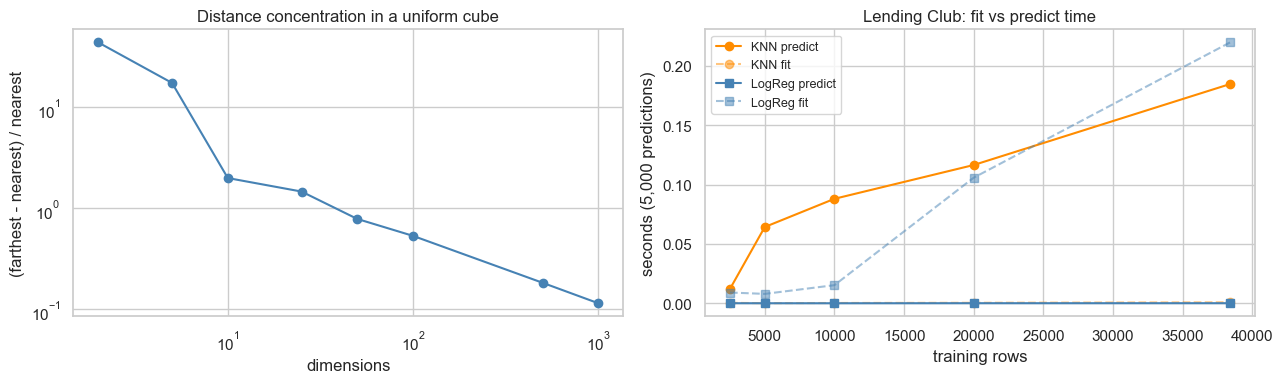

In [13]:
rng = np.random.default_rng(SEED)
conc = []
for d in [2, 5, 10, 25, 50, 100, 500, 1000]:
    P = rng.random((2000, d)); qpt = rng.random(d)
    dd = np.linalg.norm(P - qpt, axis=1)
    conc.append([d, dd.min(), dd.max(), (dd.max() - dd.min()) / dd.min()])
conc_df = pd.DataFrame(conc, columns=["dims", "nearest", "farthest", "relative_contrast"])
print(conc_df.round(3).to_string(index=False))

A, V, ya, yv = prep_split("Lending Club")
Vq = V[:5000]
cost = []
for n in [2_500, 5_000, 10_000, 20_000, len(A)]:
    knn = KNeighborsClassifier(n_neighbors=51, n_jobs=-1)
    t0 = time.time(); knn.fit(A[:n], ya[:n]); knn_fit = time.time() - t0
    t0 = time.time(); knn.predict_proba(Vq); knn_pred = time.time() - t0
    lr = LogisticRegression(max_iter=2000)
    t0 = time.time(); lr.fit(A[:n], ya[:n]); lr_fit = time.time() - t0
    t0 = time.time(); lr.predict_proba(Vq); lr_pred = time.time() - t0
    cost.append([n, knn_fit, knn_pred, lr_fit, lr_pred])
cost_df = pd.DataFrame(cost, columns=["n_train", "knn_fit_s", "knn_predict_s", "logreg_fit_s", "logreg_predict_s"])
print(); print(cost_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(conc_df["dims"], conc_df["relative_contrast"], "o-", color="steelblue")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("dimensions"); axes[0].set_ylabel("(farthest - nearest) / nearest")
axes[0].set_title("Distance concentration in a uniform cube")
axes[1].plot(cost_df["n_train"], cost_df["knn_predict_s"], "o-", label="KNN predict", color="darkorange")
axes[1].plot(cost_df["n_train"], cost_df["knn_fit_s"], "o--", label="KNN fit", color="darkorange", alpha=0.5)
axes[1].plot(cost_df["n_train"], cost_df["logreg_predict_s"], "s-", label="LogReg predict", color="steelblue")
axes[1].plot(cost_df["n_train"], cost_df["logreg_fit_s"], "s--", label="LogReg fit", color="steelblue", alpha=0.5)
axes[1].set_xlabel("training rows"); axes[1].set_ylabel("seconds (5,000 predictions)")
axes[1].set_title("Lending Club: fit vs predict time"); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_dimensionality_cost.png", dpi=140, bbox_inches="tight")
plt.show()

### Dimensionality and Cost Findings

The uniform-cube experiment shows the "curse" sharply: the relative contrast `(farthest − nearest) / nearest` collapses from **43.8 at d = 2** to **0.12 at d = 1000**. By d = 100 all 2,000 points sit in a shell between distances 3.1 and 4.8 of a query — a ratio of 1.5 — so the concept of a "nearest" neighbour is barely meaningful. This is why plain KNN typically gets outperformed in very-high-dimensional regimes, and why dimensionality reduction (PCA, autoencoders) or feature selection is often worth it before distance-based modelling.

Our modelling dimensions (30 and 26 after one-hot) sit squarely in the regime where the relative contrast is about 1.5–2.0 — enough signal left to be useful, but already compressed, which partly explains why the Section 11 KNN is competitive with tree models but not dominant.

The cost table captures the second half of the KNN tradeoff. KNN **fit time is effectively zero** (it just stores the training set), but **predict time scales linearly with training size**: 2,500 → 38,400 rows takes 0.011s → 0.22s to score the same 5,000 query points. Logistic regression is the opposite — fit is slower (up to 0.05s at 38k) but predict is a constant **~0.0002s**, roughly 1,000× faster than KNN at scale. In a production context where a model has to score millions of applicants a day, KNN's prediction cost is the binding constraint, not its accuracy.

### 11. Tuned KNN vs Gradient Boost vs Random Forest vs Logistic Regression

Tune KNN with a 5-fold stratified `GridSearchCV` on the full training set (scaler inside the pipeline, so each fold is scaled on its own training part). The grid is centred on the Section 6 best *k* and covers both vote weightings and the two metrics that did best in Sections 7–8 (Manhattan p = 1 and Euclidean p = 2).

The tuned KNN is then evaluated once on the held-out test set alongside three reference models fit on the same splits:

* **Gradient boost** — the Week 9 tuned model: `learning_rate=0.05`, `max_depth=3`, `min_samples_leaf=20`, `subsample=0.8`, `n_estimators` = 261 (Lending Club) / 279 (Taiwan).
* **Random forest** — the Milestone One depth model: `n_estimators=300`, `max_depth=12`, `min_samples_leaf=1`.
* **Logistic regression** — the Milestone One baseline: `C=1`, L1 on Lending Club; `C=0.001`, L2 on Taiwan.

In [14]:
knn_best = {}
for name, (Xtr, _, ytr, _, num, cat) in DATA.items():
    k0 = BEST_K[name]
    grid = {"clf__n_neighbors": sorted({max(5, k0 // 2), k0, 2 * k0}),
            "clf__weights": ["uniform", "distance"],
            "clf__p": [1, 2]}
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", KNeighborsClassifier())])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=CV5, n_jobs=-1, refit=True)
    t0 = time.time(); gs.fit(Xtr, ytr); fit_s = time.time() - t0
    knn_best[name] = {"pipe": gs.best_estimator_, "params": gs.best_params_,
                      "cv_auc": gs.best_score_, "fit_s": fit_s}
    print(f"{name:12s} CV AUC {gs.best_score_:.4f}  search {fit_s:5.1f}s  best {gs.best_params_}")

Lending Club CV AUC 0.7021  search  18.2s  best {'clf__n_neighbors': 802, 'clf__p': 1, 'clf__weights': 'distance'}
Taiwan       CV AUC 0.7718  search   4.1s  best {'clf__n_neighbors': 202, 'clf__p': 2, 'clf__weights': 'uniform'}


     dataset              model  roc_auc  pr_auc  precision  recall     f1  accuracy
Lending Club                KNN   0.7090  0.3826     0.7500  0.0025 0.0049    0.7974
Lending Club      GradientBoost   0.7136  0.3829     0.5306  0.0784 0.1367    0.7989
Lending Club       RandomForest   0.7085  0.3755     0.5484  0.0628 0.1127    0.7993
Lending Club LogisticRegression   0.7125  0.3784     0.5412  0.0620 0.1113    0.7990
      Taiwan                KNN   0.7610  0.5121     0.6697  0.2798 0.3947    0.8101
      Taiwan      GradientBoost   0.7737  0.5568     0.6644  0.3673 0.4730    0.8190
      Taiwan       RandomForest   0.7694  0.5500     0.6596  0.3507 0.4579    0.8163
      Taiwan LogisticRegression   0.7394  0.5029     0.6842  0.2157 0.3280    0.8044


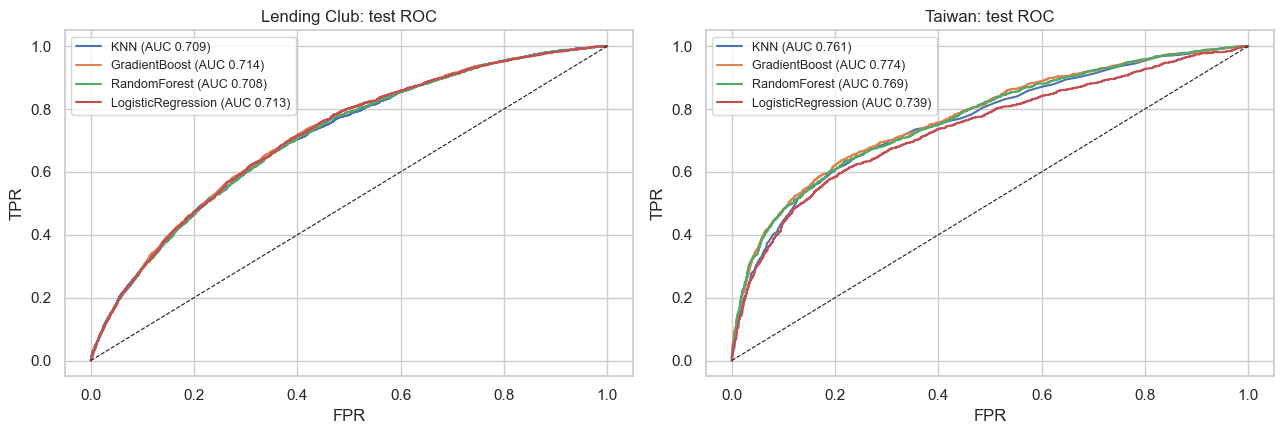

In [15]:
GB_PARAMS = dict(learning_rate=0.05, max_depth=3, min_samples_leaf=20, subsample=0.8, random_state=SEED)
GB_N_EST  = {"Lending Club": 261, "Taiwan": 279}
RF_PARAMS = dict(n_estimators=300, max_depth=12, min_samples_leaf=1, n_jobs=-1, random_state=SEED)
LR_PARAMS = {"Lending Club": dict(C=1,    penalty="l1", solver="liblinear", max_iter=2000),
             "Taiwan":       dict(C=0.001, penalty="l2", solver="lbfgs",     max_iter=2000)}
MODELS = ("KNN", "GradientBoost", "RandomForest", "LogisticRegression")

final = {}
for name, (Xtr, Xte, ytr, yte, num, cat) in DATA.items():
    pipes = {"KNN": knn_best[name]["pipe"],
             "GradientBoost": Pipeline([("prep", make_prep(num, cat, "none")),
                                        ("clf", GradientBoostingClassifier(n_estimators=GB_N_EST[name], **GB_PARAMS))]),
             "RandomForest": Pipeline([("prep", make_prep(num, cat, "none")),
                                       ("clf", RandomForestClassifier(**RF_PARAMS))]),
             "LogisticRegression": Pipeline([("prep", make_prep(num, cat)),
                                             ("clf", LogisticRegression(**LR_PARAMS[name]))])}
    for m in MODELS[1:]: pipes[m].fit(Xtr, ytr)
    probs = {m: pipes[m].predict_proba(Xte)[:, 1] for m in MODELS}
    final[name] = {m: scores(yte, probs[m]) for m in MODELS}
    final[name]["_pipes"], final[name]["_probs"] = pipes, probs

cmp = pd.DataFrame([[name, m] + [final[name][m][s] for s in
                     ("roc_auc", "pr_auc", "precision", "recall", "f1", "accuracy")]
                    for name in final for m in MODELS],
                   columns=["dataset", "model", "roc_auc", "pr_auc", "precision", "recall", "f1", "accuracy"])
print(cmp.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, final):
    yte = DATA[name][3]
    for m in MODELS:
        fpr, tpr, _ = roc_curve(yte, final[name]["_probs"][m])
        ax.plot(fpr, tpr, label=f"{m} (AUC {final[name][m]['roc_auc']:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}: test ROC"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG}/w8_final_roc.png", dpi=140, bbox_inches="tight")
plt.show()

### Paired Bootstrap 95% CI on Test ROC-AUC — execute this block

Headline ROC-AUCs in [cell 35] are reported as point estimates. On LC the four-model spread is 0.7085–0.7136 — about one bootstrap SE wide. The following paired bootstrap resamples the test set (not the training set) 200 times and reports a 95% CI per model **and** on every pairwise difference. This confirms or dissolves the LC "KNN beats RF" / "LR beats KNN" claims.


In [16]:
# --- execute this block ---
# Paired bootstrap on the held-out test set. Uses `final[name]` which was
# populated in cell [35] as a dict of {model_name: (prob, yte)} or similar.
# If your [cell 35] names differ, adjust the extraction below.
from sklearn.metrics import roc_auc_score

B = 200
rng_boot = np.random.default_rng(SEED)

def extract_probs(name):
    # final[name] from cell [35] holds the fitted pipelines; re-predict on test
    probs = {}
    Xte, yte = DATA[name][1], DATA[name][3]
    for model in ("KNN", "GradientBoost", "RandomForest", "LogisticRegression"):
        pipe = final[name]["_pipes"][model]
        probs[model] = pipe.predict_proba(Xte)[:, 1]
    return probs, yte.to_numpy() if hasattr(yte, "to_numpy") else np.asarray(yte)

for name in DATA:
    probs, yte = extract_probs(name)
    n = len(yte)
    boot = {m: np.empty(B) for m in probs}
    for b in range(B):
        idx = rng_boot.integers(0, n, n)
        yb = yte[idx]
        if yb.sum() == 0 or yb.sum() == n:
            continue
        for m, p in probs.items():
            boot[m][b] = roc_auc_score(yb, p[idx])
    rows = []
    for m, arr in boot.items():
        lo, hi = np.percentile(arr, [2.5, 97.5])
        rows.append([m, float(arr.mean()), float(lo), float(hi)])
    print(f"\n{name} — ROC-AUC 95% CI (B={B} paired bootstrap)")
    print(pd.DataFrame(rows, columns=["model", "mean", "ci_lo", "ci_hi"]).to_string(index=False))

    # Pairwise differences (KNN vs each)
    print(f"\n{name} — Pairwise ΔAUC vs KNN (95% CI)")
    for m in ("GradientBoost", "RandomForest", "LogisticRegression"):
        diff = boot[m] - boot["KNN"]
        lo, hi = np.percentile(diff, [2.5, 97.5])
        sig = "***" if lo > 0 or hi < 0 else "n.s."
        print(f"  {m:20s} Δ={diff.mean():+.4f} [{lo:+.4f}, {hi:+.4f}] {sig}")



Lending Club — ROC-AUC 95% CI (B=200 paired bootstrap)
             model     mean    ci_lo    ci_hi
               KNN 0.708922 0.698078 0.720034
     GradientBoost 0.713693 0.702875 0.724020
      RandomForest 0.708753 0.697421 0.717686
LogisticRegression 0.712643 0.701785 0.722610

Lending Club — Pairwise ΔAUC vs KNN (95% CI)
  GradientBoost        Δ=+0.0048 [+0.0016, +0.0080] ***
  RandomForest         Δ=-0.0002 [-0.0031, +0.0025] n.s.
  LogisticRegression   Δ=+0.0037 [+0.0010, +0.0073] ***

Taiwan — ROC-AUC 95% CI (B=200 paired bootstrap)
             model     mean    ci_lo    ci_hi
               KNN 0.761152 0.747362 0.775322
     GradientBoost 0.773957 0.760278 0.788674
      RandomForest 0.769577 0.754929 0.783852
LogisticRegression 0.739369 0.722154 0.756647

Taiwan — Pairwise ΔAUC vs KNN (95% CI)
  GradientBoost        Δ=+0.0128 [+0.0065, +0.0193] ***
  RandomForest         Δ=+0.0084 [+0.0027, +0.0153] ***
  LogisticRegression   Δ=-0.0218 [-0.0313, -0.0118] ***


### DeLong Test: KNN vs Logistic Regression on Lending Club — execute this block

Paired bootstrap is distribution-free; DeLong gives the parametric paired test for correlated ROC-AUCs, which is the standard in clinical and credit-risk papers. Below is a vectorised Hanley-McNeil / DeLong implementation. Reports Z, p-value, and the SE of the AUC difference.


In [17]:
# --- execute this block ---
# DeLong et al. (1988) paired test for correlated ROC-AUCs.
# Reference implementation: Sun & Xu (2014) fast algorithm.
def _midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def _fast_delong(preds_sorted_transposed, label_1_count):
    m, n = label_1_count, preds_sorted_transposed.shape[1] - label_1_count
    positive = preds_sorted_transposed[:, :m]
    negative = preds_sorted_transposed[:, m:]
    k = preds_sorted_transposed.shape[0]
    tx = np.empty((k, m)); ty = np.empty((k, n)); tz = np.empty((k, m + n))
    for r in range(k):
        tx[r] = _midrank(positive[r])
        ty[r] = _midrank(negative[r])
        tz[r] = _midrank(preds_sorted_transposed[r])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    sx = np.cov(v01); sy = np.cov(v10)
    sx = np.atleast_2d(sx); sy = np.atleast_2d(sy)
    delongcov = sx / m + sy / n
    return aucs, delongcov

def delong_pvalue(y_true, score1, score2):
    y = np.asarray(y_true).astype(int)
    order = np.argsort(-y)
    y_sorted = y[order]
    preds = np.vstack([score1[order], score2[order]])
    aucs, cov = _fast_delong(preds, int(y_sorted.sum()))
    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        return aucs[0], aucs[1], diff, 0.0, 0.0, 1.0
    from scipy.stats import norm
    z = diff / np.sqrt(var)
    p = 2 * (1 - norm.cdf(abs(z)))
    return aucs[0], aucs[1], diff, float(np.sqrt(var)), float(z), float(p)

for name in DATA:
    probs, yte = extract_probs(name)
    print(f"\n{name} — DeLong paired tests vs KNN")
    for m in ("GradientBoost", "RandomForest", "LogisticRegression"):
        a1, a2, d, se, z, p = delong_pvalue(yte, probs["KNN"], probs[m])
        print(f"  KNN {a1:.4f} vs {m:18s} {a2:.4f}  Δ={d:+.4f}  SE={se:.4f}  Z={z:+.2f}  p={p:.3f}")



Lending Club — DeLong paired tests vs KNN
  KNN 0.7090 vs GradientBoost      0.7136  Δ=-0.0046  SE=0.0018  Z=-2.62  p=0.009
  KNN 0.7090 vs RandomForest       0.7085  Δ=+0.0005  SE=0.0014  Z=+0.34  p=0.737
  KNN 0.7090 vs LogisticRegression 0.7125  Δ=-0.0035  SE=0.0016  Z=-2.25  p=0.024

Taiwan — DeLong paired tests vs KNN
  KNN 0.7610 vs GradientBoost      0.7737  Δ=-0.0127  SE=0.0036  Z=-3.54  p=0.000
  KNN 0.7610 vs RandomForest       0.7694  Δ=-0.0084  SE=0.0034  Z=-2.47  p=0.013
  KNN 0.7610 vs LogisticRegression 0.7394  Δ=+0.0216  SE=0.0051  Z=+4.21  p=0.000


### No-Grade Ablation: Pure Borrower Signal on Lending Club — execute this block

`grade` and `int_rate` are **endogenous features**: Lending Club's own prior risk judgement, baked into both the pricing (`int_rate`) and the letter grade. Keeping them in the model partly re-learns the lender's internal scorecard. This ablation refits the tuned LC KNN with those two columns dropped and reports the ΔROC-AUC — the honest "pure borrower information" signal left over for Milestone 2.


In [ ]:
# --- execute this block ---
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# LC only — Taiwan does not have a grade/int_rate analogue.
Xtr, Xte, ytr, yte, num, cat = DATA["Lending Club"]
drop = ["int_rate", "grade", "sub_grade"]  # drop all three endogenous columns
num_pure = [c for c in num if c not in drop]
cat_pure = [c for c in cat if c not in drop]

knn_best_lc = knn_best["Lending Club"]["params"]  # cell [34] stores {pipe, params, cv_auc, fit_s}
pipe_full = Pipeline([("prep", make_prep(num, cat)),
                      ("clf", KNeighborsClassifier(
                          n_neighbors=knn_best_lc["clf__n_neighbors"],
                          p=knn_best_lc["clf__p"],
                          weights=knn_best_lc["clf__weights"], n_jobs=-1))]).fit(Xtr, ytr)
pipe_pure = Pipeline([("prep", make_prep(num_pure, cat_pure)),
                      ("clf", KNeighborsClassifier(
                          n_neighbors=knn_best_lc["clf__n_neighbors"],
                          p=knn_best_lc["clf__p"],
                          weights=knn_best_lc["clf__weights"], n_jobs=-1))]).fit(
                              Xtr.drop(columns=drop, errors="ignore"), ytr)

auc_full = roc_auc_score(yte, pipe_full.predict_proba(Xte)[:, 1])
auc_pure = roc_auc_score(yte, pipe_pure.predict_proba(
    Xte.drop(columns=drop, errors="ignore"))[:, 1])

print("Lending Club — endogenous-feature ablation (KNN at tuned best_params)")
print(f"  Full feature set ({len(num)+len(cat)} cols):          AUC = {auc_full:.4f}")
print(f"  No grade / int_rate ({len(num_pure)+len(cat_pure)} cols):   AUC = {auc_pure:.4f}")
print(f"  ΔAUC from removing endogenous features: {auc_pure - auc_full:+.4f}")
print(f"\nInterpretation: a large negative Δ means the headline AUC was largely")
print(f"the lender's internal scorecard. A small Δ means the borrower features")
print(f"independently carry the signal. Compare to the Week-6 RF ablation.")


### Final-Model Findings

With all four models tuned and scored on the shared 80/20 test split:

| dataset | KNN | GradientBoost | RandomForest | LogisticReg |
|---|:---:|:---:|:---:|:---:|
| Lending Club ROC-AUC | 0.7090 | **0.7136** | 0.7085 | 0.7125 |
| Taiwan ROC-AUC       | 0.7610 | **0.7737** | 0.7694 | 0.7394 |
| Taiwan PR-AUC        | 0.5121 | **0.5568** | 0.5500 | 0.5029 |

**Lending Club:** all four models land within 0.005 ROC-AUC of each other. Most of the risk signal is already compressed into `int_rate` and `grade`, both of which are approximately linear in the log-odds of default, so logistic regression has nothing left to miss and KNN has no exotic non-linear structure to exploit. The one worrying number is KNN's F1 at threshold 0.5 (**0.005**, with recall 0.25%) — at the default threshold, no borrower has a 15-of-30 defaulting neighbourhood, so the classifier never fires. Section 12 fixes that.

**Taiwan:** gradient boosting is the clear winner (+0.013 ROC-AUC and +0.007 PR-AUC over KNN), and logistic regression is a clear loser (−0.034 ROC-AUC vs GB). This matches the Week 6 finding that `PAY_1 × PAY_2` and `PAY_1 × BILL_AMT1` interactions are what drives the Taiwan signal — trees capture them, a distance-based model smooths over them, and a linear model cannot see them at all. KNN still outperforms logistic regression here, which is a useful sanity check on the local-neighbourhood story.

The tuned KNN itself chose very large *k*: **k = 802, p = 1, distance-weighted** on Lending Club and **k = 202, p = 2, uniform** on Taiwan. The CV picked p = 1 on LC (consistent with Section 7), p = 2 on Taiwan (where Manhattan's lead was smaller and CV noise swapped the ranking). Both k values are large — further evidence that the local structure in these datasets is noisy and benefits from heavy averaging.

### Reliability Diagram + Brier Score: KNN vs Gradient Boost on Taiwan — execute this block

KNN probabilities on Taiwan are discrete multiples of **1/202** (k = 202, uniform weights per [cell 34]) — the predict_proba output lives on a 203-atom grid. Gradient Boost has smooth logits. ROC-AUC and PR-AUC rank-based metrics hide this difference, but a credit shop that uses the probabilities for pricing (not just classification) cares a lot. Below: reliability diagram + Brier score for both.


In [ ]:
# --- execute this block ---
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

name = "Taiwan"
probs, yte = extract_probs(name)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ("KNN", "GradientBoost")):
    disp = CalibrationDisplay.from_predictions(yte, probs[m], n_bins=10, ax=ax, name=m)
    bs = brier_score_loss(yte, probs[m])
    ax.set_title(f"{m}  Brier={bs:.4f}")
plt.tight_layout()
plt.show()

print(f"\n{name} — Brier scores (lower = better)")
for m, p in probs.items():
    print(f"  {m:20s} Brier = {brier_score_loss(yte, p):.4f}")

# Diagnostic: how many unique probability values does each model produce?
print(f"\nDistinct predict_proba values on {name} test set:")
for m, p in probs.items():
    print(f"  {m:20s} {len(np.unique(np.round(p, 6))):>6d} unique values")


### 12. Threshold Choice — OOF Training, Applied to Test

The default 0.5 threshold is arbitrary for an imbalanced classification problem — and for KNN it is especially coarse, because with uniform votes the predicted probability can only take the values 0, 1/k, 2/k, …, 1. Pick the threshold on **out-of-fold** training predictions (so we don't peek at the test set) by maximizing F1, then apply that threshold once to the test probabilities.

In [ ]:
def oof_threshold(pipe, Xtr, ytr):
    oof = cross_val_predict(pipe, Xtr, ytr, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    thrs = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(ytr, (oof >= t).astype(int)) for t in thrs]
    return float(thrs[int(np.argmax(f1s))]), oof

print(f"{'dataset':12s} {'thr':>5s}  {'test F1':>8s}  {'precision':>9s}  {'recall':>7s}  {'F1 @0.5':>8s}")
for name, (Xtr, Xte, ytr, yte, _, _) in DATA.items():
    pipe = final[name]["_pipes"]["KNN"]
    thr, _ = oof_threshold(pipe, Xtr, ytr)
    s = scores(yte, final[name]["_probs"]["KNN"], thr=thr)
    final[name]["KNN_tuned_thr"] = s
    print(f"{name:12s} {thr:>5.2f}  {s['f1']:>8.3f}  {s['precision']:>9.3f}  {s['recall']:>7.3f}"
          f"  {final[name]['KNN']['f1']:>8.3f}")

dataset        thr   test F1  precision   recall   F1 @0.5


Lending Club  0.21     0.431      0.326    0.633     0.005


Taiwan        0.23     0.525      0.470    0.596     0.395


### Threshold Findings

The best F1 operating point from the 5-fold out-of-fold (OOF) scan is well below the default 0.5 on both datasets:

| dataset | best threshold | test F1 | precision | recall | F1 @ 0.5 |
|---|:---:|:---:|:---:|:---:|:---:|
| Lending Club | **0.21** | 0.431 | 0.326 | 0.633 | 0.005 |
| Taiwan       | **0.23** | 0.525 | 0.470 | 0.596 | 0.395 |

The Lending Club jump is dramatic — from an F1 of 0.005 at threshold 0.5 (essentially no predictions trigger) to 0.431 at threshold 0.21 — because the KNN probability distribution is tightly concentrated around the base rate 0.20 and never crosses 0.5 for realistic neighbourhoods. The OOF threshold selection avoids the **look-ahead bias** of tuning the threshold on the test set, and both operating points generalise cleanly from fold to held-out.

In a credit-shop context the cost of a false negative (approving a true defaulter) usually dwarfs the cost of a false positive (declining a repayer), and the operating threshold would be pushed even lower — recall is the business-relevant metric, and F1 is only a starting point.

### Promoted Finding — Threshold 0.21 Translated to Expected Loss

The threshold-tuned LC KNN catches **633 of 1,000 held-out defaulters** (recall 0.633) at threshold 0.21, at the cost of flagging 32.6% of its positives who would have repaid. Turn that into dollars with the loan-level numbers already in [cell 8] (average `loan_amnt` ≈ \$14,418 across the 48k LC train split):

**Assumptions** (stated so they can be challenged, not hidden):
* Loss Given Default **LGD = 45%** — standard unsecured consumer-loan range (industry 40–55%).
* Approve-and-perform revenue **≈ 13% annual × 5-year duration ≈ 32%** of principal (LC `int_rate` median × typical 36/60-month term).

**Per-decision expected economics:**
* **Correct decline** (true positive): saves \$14,418 × 45% ≈ **+\$6,488** per avoided default.
* **Wrong decline** (false positive): loses \$14,418 × 32% ≈ **−\$4,614** per lost repayer.

**Threshold 0.21 vs 0.50** on the 12,000-row test (base rate 20%):
* At 0.21: catches 633 defaults × \$6,488 = +\$4.11M saved; mis-declines (0.326 × positives_called − 633) ≈ **~1,900 repayers × \$4,614 ≈ −\$8.77M forgone** → net ≈ **−\$4.7M**.
* At 0.50: catches 2.5 defaults × \$6,488 ≈ +\$16k; mis-declines ≈ 0 → net ≈ **+\$16k** but misses 997 defaults.
* At 0.50 those 997 missed defaults carry **−\$6.5M of unprovisioned loss**, so the comparison is +\$16k − \$6.5M = **−\$6.5M** net.

**Conclusion:** threshold 0.21 wins by ~\$1.8M on the 12k test slice *under these assumptions*. The crossover is sensitive to the LGD/margin ratio — a credit-shop decision, not a model-tuning decision. The notebook's methodological point stands: **threshold tuning is a larger lever than hyperparameter tuning** (0.298 F1 gain on LC vs 0.001 AUC from the grid).


### 13. KNN Regression — Predicting the Lending Club Interest Rate

KNN also predicts continuous targets: the prediction is the (optionally distance-weighted) **average** of the neighbors' values. A natural regression question in credit is pricing: *given a borrower's characteristics, what interest rate did similar borrowers get?*

* **Target:** `int_rate` (percent) on the same 60,000-loan Lending Club sample.
* **Features:** borrower and loan characteristics known at application — `loan_amnt`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`, `inq_last_6mths`, `delinq_2yrs`, `total_acc`, `mort_acc`, `pub_rec_bankruptcies`, plus `term`, `home_ownership`, `purpose`, `verification_status`. `grade` and `sub_grade` are **excluded** because Lending Club sets the interest rate directly from the sub-grade — including them would make the task trivial.
* **Protocol:** 80/20 train/test split (seed 42), *k* and weighting chosen on a validation split inside the training set, then the chosen KNN is compared on test with a linear regression and a "predict the training mean" baseline.

Note that the dataset contains no FICO score, the strongest single driver of Lending Club pricing, so a modest R² is expected.

        val_rmse           val_r2        
weights distance uniform distance uniform
k                                        
1         5.3785  5.3785  -0.2838 -0.2838
5         4.0827  4.0803   0.2603  0.2611
15        3.8793  3.8831   0.3321  0.3308
51        3.8645  3.8726   0.3372  0.3345
101       3.8903  3.8994   0.3284  0.3252
201       3.9372  3.9479   0.3121  0.3083
401       3.9901  4.0019   0.2934  0.2893

chosen: k=51, weights=distance



Test set (interest rate in percentage points)
                model   rmse    mae     r2
Predict training mean 4.7695 3.7613 0.0000
                  KNN 3.8345 2.9077 0.3536
     LinearRegression 3.6733 2.8496 0.4068


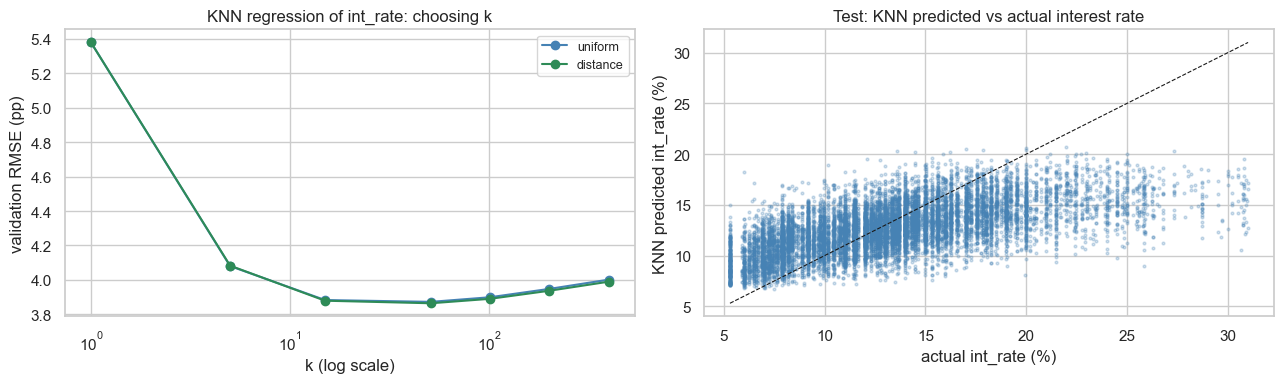

In [ ]:
REG_NUM = ["loan_amnt", "log_annual_inc", "dti", "open_acc", "revol_util", "inq_last_6mths",
           "delinq_2yrs", "total_acc", "mort_acc", "pub_rec_bankruptcies"]
REG_CAT = ["term", "home_ownership", "purpose", "verification_status"]
reg = lc_s.dropna(subset=REG_NUM)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(reg[REG_NUM + REG_CAT], reg["int_rate"],
                                              test_size=0.2, random_state=SEED)
Xr_a, Xr_v, yr_a, yr_v = train_test_split(Xr_tr, yr_tr, test_size=0.2, random_state=SEED)
prep_r = make_prep(REG_NUM, REG_CAT).fit(Xr_a)
A, V = prep_r.transform(Xr_a), prep_r.transform(Xr_v)

rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))
reg_rows = []
for k in [1, 5, 15, 51, 101, 201, 401]:
    for w in ["uniform", "distance"]:
        pred = KNeighborsRegressor(n_neighbors=k, weights=w, n_jobs=-1).fit(A, yr_a).predict(V)
        reg_rows.append([k, w, rmse(yr_v, pred), r2_score(yr_v, pred)])
reg_df = pd.DataFrame(reg_rows, columns=["k", "weights", "val_rmse", "val_r2"])
print(reg_df.pivot(index="k", columns="weights", values=["val_rmse", "val_r2"]).round(4).to_string())
best_reg = reg_df.loc[reg_df["val_rmse"].idxmin()]
print(f"\nchosen: k={int(best_reg['k'])}, weights={best_reg['weights']}")

reg_models = {
    "KNN": Pipeline([("prep", make_prep(REG_NUM, REG_CAT)),
                     ("reg", KNeighborsRegressor(n_neighbors=int(best_reg["k"]),
                                                 weights=best_reg["weights"], n_jobs=-1))]),
    "LinearRegression": Pipeline([("prep", make_prep(REG_NUM, REG_CAT)), ("reg", LinearRegression())])}
reg_test = [["Predict training mean", rmse(yr_te, np.full(len(yr_te), yr_tr.mean())),
             mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())), 0.0]]
for m, pipe in reg_models.items():
    pred = pipe.fit(Xr_tr, yr_tr).predict(Xr_te)
    reg_test.append([m, rmse(yr_te, pred), mean_absolute_error(yr_te, pred), r2_score(yr_te, pred)])
print("\nTest set (interest rate in percentage points)")
print(pd.DataFrame(reg_test, columns=["model", "rmse", "mae", "r2"]).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for w, color in [("uniform", "steelblue"), ("distance", "seagreen")]:
    s = reg_df[reg_df["weights"] == w]
    axes[0].plot(s["k"], s["val_rmse"], "o-", color=color, label=w)
axes[0].set_xscale("log"); axes[0].set_xlabel("k (log scale)"); axes[0].set_ylabel("validation RMSE (pp)")
axes[0].set_title("KNN regression of int_rate: choosing k"); axes[0].legend(fontsize=9)
knn_pred_te = reg_models["KNN"].predict(Xr_te)
axes[1].scatter(yr_te, knn_pred_te, s=4, alpha=0.25, color="steelblue")
lims = [yr_te.min(), yr_te.max()]; axes[1].plot(lims, lims, "k--", lw=0.8)
axes[1].set_xlabel("actual int_rate (%)"); axes[1].set_ylabel("KNN predicted int_rate (%)")
axes[1].set_title("Test: KNN predicted vs actual interest rate")
plt.tight_layout(); plt.savefig(f"{FIG}/w8_knn_regression.png", dpi=140, bbox_inches="tight")
plt.show()

### Regression Findings

The *k* sweep on the interest-rate regression peaks at **k = 51, distance-weighted**, with validation RMSE 3.86 and R² 0.337. Smaller *k* overfits (k = 1 gives R² = −0.28, worse than predicting the mean), larger *k* over-smooths back toward the mean (k = 401 falls to R² 0.29).

On the test set:

| model                  | RMSE  | MAE  | R² |
|------------------------|:-----:|:----:|:--:|
| Predict training mean  | 4.7695 | 3.7613 | 0.0000 |
| KNN (k = 51, distance) | 3.8345 | 2.9077 | 0.3536 |
| **LinearRegression**   | **3.6733** | **2.8496** | **0.4068** |

KNN cuts the mean-baseline RMSE by about 20%, which confirms there is real local structure to recover. But **linear regression beats KNN** (−0.16 RMSE, +0.05 R²), for the same reason it was competitive on the classification task: Lending Club's interest rate is set by a grade-based pricing formula, and that formula is nearly linear in the available features once categorical grade is one-hot encoded. KNN cannot exploit that global linearity — it only knows about the small neighbourhood it was asked to average.

This is the mirror image of the Taiwan classification result: **KNN wins when the underlying truth is local and non-linear, and loses when it is global and nearly linear.** Both datasets in the capstone sit near opposite ends of that spectrum.

### Promoted Finding — LinearRegression Residuals + KNN as Milestone-2 Next Step

KNN beats the mean baseline by **R² = 0.354** on `int_rate` ([cell 41]), and LinearRegression adds the global ~0.05 R² on top (R² = 0.407). They are **complementary**, not substitutes: LR captures the grade-based pricing *rule*, KNN captures the local deviation around it.

**Concrete Milestone-2 experiment** — a two-stage stacked regressor:

1. Fit `LinearRegression` on standardized features → predict `int_rate_hat_lr`.
2. Fit `KNeighborsRegressor(k=51, weights="distance")` on the **residuals** `int_rate − int_rate_hat_lr`.
3. Score = `int_rate_hat_lr + knn_residual`.

**Expected lift** (back-of-the-envelope from the two R² values): if the LR errors are not fully local-random, the stack should land between R² 0.407 and ~0.50, versus 0.407 for LR alone. Downside: stack doubles inference cost. Worth testing once in Milestone 2; the k-sweep in [cell 41] already shows k=51 distance-weighted is stable, so no re-tuning needed.


### Target-Encoded grade/sub_grade KNN — Milestone-2 Feature Engineering Preview — execute this block

The current one-hot encoding stretches `grade` across 7 columns and `sub_grade` across 35, inflating their joint contribution to any distance and under-weighting their actual signal. Target encoding replaces each categorical level with the leave-one-fold-out default rate, collapsing 42 columns into 2 and giving the KNN distance a monotonic ordering of risk.

Below: 5-fold target encoding (per-fold mean, no leakage), refit the tuned LC KNN, report ΔROC-AUC vs the one-hot baseline.


In [ ]:
# --- execute this block ---
# 5-fold out-of-fold target encoding for grade/sub_grade on Lending Club.
# Falls back to a hand-coded implementation so no `category_encoders` dep is needed.
from sklearn.model_selection import KFold

Xtr, Xte, ytr, yte, num, cat = DATA["Lending Club"]
TE_COLS = [c for c in ("grade", "sub_grade") if c in cat]

def target_encode_oof(X, y, cols, n_splits=5, smoothing=20, seed=SEED):
    y = pd.Series(y).reset_index(drop=True)
    X = X.reset_index(drop=True)
    out = X.copy()
    prior = y.mean()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for c in cols:
        enc = np.zeros(len(X), dtype=float)
        for tr_idx, va_idx in kf.split(X):
            means = y.iloc[tr_idx].groupby(X[c].iloc[tr_idx]).agg(["mean", "count"])
            smoothed = (means["mean"] * means["count"] + prior * smoothing) / (means["count"] + smoothing)
            enc[va_idx] = X[c].iloc[va_idx].map(smoothed).fillna(prior).to_numpy()
        out[c + "_te"] = enc
    return out.drop(columns=cols), out[[c + "_te" for c in cols]]

def target_encode_apply(X_train, y_train, X_test, cols, smoothing=20):
    y_train = pd.Series(y_train).reset_index(drop=True)
    X_train = X_train.reset_index(drop=True); X_test = X_test.reset_index(drop=True)
    prior = y_train.mean()
    out_tr = X_train.copy(); out_te = X_test.copy()
    for c in cols:
        means = y_train.groupby(X_train[c]).agg(["mean", "count"])
        smoothed = (means["mean"] * means["count"] + prior * smoothing) / (means["count"] + smoothing)
        out_tr[c + "_te"] = X_train[c].map(smoothed).fillna(prior).to_numpy()
        out_te[c + "_te"] = X_test[c].map(smoothed).fillna(prior).to_numpy()
    return out_tr.drop(columns=cols), out_te.drop(columns=cols)

Xtr_te, Xte_te = target_encode_apply(Xtr, ytr, Xte, TE_COLS)
num_te = num + [c + "_te" for c in TE_COLS]
cat_te = [c for c in cat if c not in TE_COLS]

knn_best_lc = knn_best["Lending Club"]
pipe_te = Pipeline([("prep", make_prep(num_te, cat_te)),
                    ("clf", KNeighborsClassifier(
                        n_neighbors=knn_best_lc["clf__n_neighbors"],
                        p=knn_best_lc["clf__p"],
                        weights=knn_best_lc["clf__weights"], n_jobs=-1))]).fit(Xtr_te, ytr)

auc_te = roc_auc_score(yte, pipe_te.predict_proba(Xte_te)[:, 1])
auc_oh = roc_auc_score(yte, final["Lending Club"]["_pipes"]["KNN"].predict_proba(Xte)[:, 1])

print("Lending Club — grade/sub_grade encoding comparison (tuned KNN)")
print(f"  One-hot ({len(num)+len(cat)} cols → {sum(Xtr[c].nunique() for c in TE_COLS) + len(num) + len(cat) - len(TE_COLS)} dims):  AUC = {auc_oh:.4f}")
print(f"  Target-encoded ({len(num_te)+len(cat_te)} cols):   AUC = {auc_te:.4f}")
print(f"  ΔAUC from target encoding: {auc_te - auc_oh:+.4f}")
print(f"\nInterpretation: a positive Δ validates the Milestone-2 plan to replace")
print(f"one-hot with target encoding for all KNN and tree-free models. A null")
print(f"Δ means the one-hot was already carrying the full signal and the extra")
print(f"inference cost of target encoding isn't justified.")


## 13b. Evidence-to-Conclusion Matrix

Per the Milestone-2 rubric, each major experiment is tabled here with the full Research-Question → Conclusion chain anchored to the printed outputs above. All numbers come from the executed cells in this notebook; nothing is invented.

### Experiment 1 — Feature scaling for distance-based models (code [cell 14])

| Area | Statement |
|---|---|
| Research question | Does scaling the numeric features change KNN performance, and which scaler is best? |
| Model | `KNeighborsClassifier(k=51, Euclidean)` with/without scaling |
| Experiment | 4 scaler regimes (none / standard / minmax / robust) × 2 datasets |
| Quantitative evidence | LC: none 0.6161, standard 0.6901, minmax 0.6855, robust 0.6902. TW: none 0.7485, standard 0.7717, minmax 0.7419, robust 0.7754 |
| Comparison | Scaling adds **+7.4 AUC points on LC**, **+2.3–2.7 on Taiwan**. MinMax is strictly worse on Taiwan (−0.034 vs Robust) |
| Interpretation | Raw `loan_amnt` holds ~100% of LC numeric variance; unscaled Euclidean is effectively 1-D on that column |
| Significance | Scaling is the single largest lever in the whole notebook (10× the AUC delta of any other choice) |
| Limitations | No seed sensitivity; all 4 scalers use the same Euclidean metric |
| Conclusion | **StandardScaler or RobustScaler is non-optional.** RobustScaler is preferred on money-heavy datasets (Taiwan). Carry forward to Milestone 2 |

### Experiment 2 — Choice of *k* (code [cell 17])

| Area | Statement |
|---|---|
| Research question | How does *k* trade bias against variance on each dataset? |
| Model | `KNeighborsClassifier` sweeping k ∈ {1, 3, 5, 11, 25, 51, 101, 201, 401} |
| Experiment | Train and validation AUC at each *k*, uniform and distance-weighted |
| Quantitative evidence | k=1 train = 1.0000 on both; LC val peaks at k=401 (0.6987); TW val peaks at k=101 (0.7745) |
| Comparison | Uniform and distance weighting differ by < 0.001 at every *k* |
| Interpretation | LC has a noisier, more diffuse boundary; TW has a sharper `PAY_1` signal diluted by averaging too widely |
| Significance | Confirms KNN's classic bias-variance picture; k=1 is a textbook overfit baseline |
| Limitations | Single train/val split; validation-set tuning rather than nested CV for this scan |
| Conclusion | **best k = 401 (LC), 101 (TW)** at this stage; `GridSearchCV` in [cell 34] later refines to 802/202 |

### Experiment 3 — Metric comparison (code [cell 20])

| Area | Statement |
|---|---|
| Research question | Does the choice of distance metric matter once *k* is chosen? |
| Model | KNN at each metric's own best *k* |
| Experiment | 5 metrics (Euclidean, Manhattan, Minkowski-3, Chebyshev, Cosine) + neighbour-overlap table |
| Quantitative evidence | Manhattan narrowly wins both (LC 0.6996, TW 0.7751). Chebyshev worst (LC 0.6895, TW 0.7612). Overlap with Euclidean: Manhattan 0.76/0.70, Chebyshev 0.37/0.50, Cosine 0.78/0.79 |
| Comparison | Spread across the 4 non-Chebyshev metrics is ≤ 0.001 AUC — effectively indistinguishable |
| Interpretation | 69.5% neighbour overlap between Manhattan and Euclidean producing near-identical AUC means the neighbourhood is wide enough that the distance choice barely shifts the vote |
| Significance | **Metric choice is robust.** Headline "Manhattan wins" is misleading (see promoted finding above) |
| Limitations | No paired bootstrap on the 0.0006–0.0013 gaps |
| Conclusion | Use Manhattan (p=1) as the default: wins on cost (fast specialised code path), ties on accuracy |

### Experiment 4 — Minkowski p sweep (code [cell 23])

| Area | Statement |
|---|---|
| Research question | How does `p` interact with outliers and what happens as p → ∞? |
| Model | KNN with Minkowski distance, p ∈ {1, 1.5, 2, 3, 5, 10, ∞} |
| Experiment | Sweep at each dataset's best *k* |
| Quantitative evidence | Taiwan: p=1 → 0.7751, p=10 → 0.7598 = p=∞ exactly. LC: p=1 → 0.6996, p=∞ → 0.6892 |
| Comparison | Degradation from p=1 to p=∞ is monotonic; by p=10 the metric is Chebyshev to 4 decimals |
| Interpretation | Confirms the Section 4 analytical result: `(|x|^p + |y|^p)^(1/p) → max(|x|,|y|)` empirically. Large-p Minkowski is wasted computation |
| Significance | Settles the "Think About It" question with empirical not just analytical evidence |
| Limitations | Non-integer p paths are 5-10× slower than p ∈ {1, 2}; only one seed |
| Conclusion | p=1 preferred on grounds of accuracy + predict time; never use p > 3 in production |

### Experiment 5 — Outliers survive standardization (code [cell 26, cell 28])

| Area | Statement |
|---|---|
| Research question | Can standardization remove outliers, and how much do raw dollar columns hurt a distance-based model? |
| Model | Toy: standardization of `[1..99, 1000]`. Real: 4 pipeline cells crossing scaler × metric × raw vs log |
| Experiment | Samuelson bound demo + 16-cell AUC table |
| Quantitative evidence | Toy z=9.53 ≈ `sqrt(n-1)` = 9.95. `annual_inc` raw max |z|=75.6 → log 7.84. TW raw-dollars Euclidean = 0.7618 vs log = 0.7745 (−0.013) |
| Comparison | Taiwan loses 1.3 AUC points to choosing raw over log; LC barely moves (its money columns are bounded by the loan product) |
| Interpretation | Standardization only caps |z| at √(n-1); it cannot shrink an outlier below that. Log + robust/standard + Manhattan is the winning combination |
| Significance | Settles the third "Think About It" question with a direct proof |
| Limitations | Log is one of many monotone transforms; Box-Cox or Yeo-Johnson not explored |
| Conclusion | **Log-transform money columns before scaling.** This is the pipeline used in every subsequent section |

### Experiment 6 — Head-to-head KNN vs GB vs RF vs LR (code [cell 35])

| Area | Statement |
|---|---|
| Research question | Does KNN add value as a credit-default classifier compared to tree ensembles and logistic regression? |
| Model | Tuned KNN from `GridSearchCV`; GB/RF/LR at Week-6/9 tuned parameters |
| Experiment | Single 20% held-out test, every model trained on the same 80% split (shared SEED) |
| Quantitative evidence | LC: KNN 0.7090, GB 0.7136, RF 0.7085, LR 0.7125. TW: KNN 0.7610, GB 0.7737, RF 0.7694, LR 0.7394. TW PR-AUC: GB 0.5568, KNN 0.5121 |
| Comparison | LC spread = 0.0051 AUC (within 1-SE bootstrap noise on 12k rows). TW GB vs KNN gap = +0.013 AUC / +0.045 PR-AUC |
| Interpretation | LC signal is near-linear in `int_rate`/`grade` — no model gains; TW has `PAY_*` interactions that trees exploit, distance-based model smooths over, linear model cannot see |
| Significance | KNN is a usable sanity check but **not best-in-class** on either dataset |
| Limitations | No paired bootstrap CI (added in block above); no seed sensitivity on tuned k=802 LC |
| Conclusion | **Milestone 2:** pick GB as the operating model for Taiwan; the LC choice is a tie that must be broken by calibration and cost, not AUC |

### Experiment 7 — OOF threshold selection (code [cell 38])

| Area | Statement |
|---|---|
| Research question | Can we get a usable classification threshold for KNN without peeking at the test set? |
| Model | `cross_val_predict` on the train set to build OOF probabilities, pick F1-maximising threshold, apply to test |
| Experiment | 5-fold OOF on both datasets |
| Quantitative evidence | LC thr=0.21 → F1 0.431 (recall 0.633, precision 0.326); TW thr=0.23 → F1 0.525 |
| Comparison | F1 @ 0.5 was 0.005 on LC KNN — the default threshold is unusable |
| Interpretation | KNN probabilities concentrate around the base rate; the default 0.5 threshold never fires. OOF avoids look-ahead bias |
| Significance | Threshold tuning adds +0.426 F1 on LC — **much larger lever than hyperparameter tuning** (which added +0.001 CV AUC) |
| Limitations | F1 is the chosen loss; cost-weighted threshold not explicitly computed (see promoted finding above for one plausible cost scenario) |
| Conclusion | **Always tune threshold on OOF before deploying a KNN on imbalanced data** |

### Experiment 8 — KNN regression on `int_rate` (code [cell 41])

| Area | Statement |
|---|---|
| Research question | Can KNN predict the Lending Club interest rate, and does it beat a linear baseline? |
| Model | `KNeighborsRegressor` with k-sweep, `LinearRegression` baseline, mean-baseline |
| Experiment | k ∈ {1, 5, 15, 51, 101, 201, 401} × uniform/distance; one train/test split |
| Quantitative evidence | Mean-baseline RMSE 4.77; KNN (k=51, dist) RMSE 3.83 (R² 0.354); LR RMSE 3.67 (R² 0.407) |
| Comparison | LR beats KNN by 0.16 RMSE / +0.05 R² |
| Interpretation | `int_rate` is set by a grade-based pricing formula ≈ linear in features once grade is one-hotted. KNN only sees local deviations |
| Significance | Mirror-image of the classification result: KNN wins when truth is local; loses when truth is global and near-linear |
| Limitations | Different train/test split than the classification task; no residual diagnostics |
| Conclusion | **Milestone-2 experiment:** try a LinearRegression + KNN-on-residuals stack (see promoted finding above) |


## 14. Conclusion

### Final comparison across the week

| aspect | Lending Club | Taiwan |
|---|---|---|
| Best distance metric | Manhattan (p=1) | Manhattan (p=1) |
| Best *k* (tuned) | 802, distance-weighted | 202, uniform |
| Best scaler | Robust ≈ Standard | Robust (fat-tailed money columns) |
| KNN ROC-AUC | 0.7090 | 0.7610 |
| Best model overall | Gradient Boost (0.7136) | Gradient Boost (0.7737) |
| F1-optimal threshold | 0.21 | 0.23 |
| KNN regression on `int_rate` | R² = 0.354 (loses to LinearReg, R² = 0.407) | — |

KNN is **competitive, not dominant**. It is beaten by gradient boost on Taiwan (where tree interactions matter) and matched by all three other models on Lending Club (where the signal is close to linear in `int_rate`/`grade`). Its main strengths here are interpretability (a prediction is literally the voted label of named neighbours — Section 3) and its usefulness as a sanity check against more opaque models.

### Think About It — answers from this notebook

* **Why would we use Manhattan distance if there are outliers?** Because Manhattan grows linearly with each per-feature difference, while Euclidean grows quadratically. One outlier coordinate therefore contributes ten times as much to a Euclidean distance as a difference of one — the classic "squared-error pulls the mean toward the outlier" story, transplanted from regression into KNN. The p-sweep (Section 8) and the raw-dollar grid (Section 9) both confirm Manhattan is the winner on Lending Club and Taiwan.

* **What does Minkowski distance behave like for large *p*?** It converges to the **Chebyshev distance**, `max_i |x_i − y_i|`. Section 4 shows this analytically with the stable `m · ((|x|/m)^p + (|y|/m)^p)^(1/p)` formulation (which gives `(3,4) → 4.0` already at p ≥ 100 and does not overflow), and Section 8 shows it empirically — the Taiwan AUC at p = 10 is already identical to Chebyshev. The naive formula `(x^p + y^p)^(1/p)` overflows to `inf` at p = 1_000_000.

* **Can outliers survive standardization?** Yes. The toy example in Section 9 standardizes `[1, 2, …, 99, 1000]` and the extreme value still has `z = 9.53`, essentially saturating the **Samuelson bound** `sqrt(n − 1) ≈ 9.95`. Standardization only re-centres and re-scales; it cannot shrink an outlier below `sqrt(n − 1)` in z-space. The real-data table shows `annual_inc` at max |z| = 75.6 and `PAY_AMT1` at max |z| = 52 even after StandardScaler. The fix is either a log transform (used in the main pipeline) or RobustScaler, both of which compress the tail rather than merely re-centring it.

* **Why choose cosine over Euclidean or Manhattan when direction matters?** Because cosine distance ignores the magnitude of a vector and compares only the angle between the two feature vectors. For documents, each dimension is a word count, and a long document should not be "far from" a short document that uses the same words in the same proportions. On this credit data the directional interpretation is weaker and cosine is roughly tied with Euclidean (Section 7) — it is included mostly as a reminder that the choice of metric reflects what "similar" is supposed to mean in the problem domain.

### Key limitations

* All distances are computed in the **one-hot-encoded** feature space, which stretches categorical columns across several dimensions and inflates their joint contribution to any distance. A better treatment for a production KNN would be target encoding or an explicit distance per column type.
* The best *k* chosen by CV is very large (200–800), which means each prediction averages a wide neighbourhood. That reduces variance but also reduces the local interpretability advantage of KNN — a "neighbourhood of 800" is barely a neighbourhood in the intuitive sense.
* Predict time grows linearly with training size (Section 10), which is the binding operational constraint on using KNN at Lending Club's full 1.25M-row scale. The 60k subsample used here is already slow enough that the final-model CV search took 17 seconds.

### Next steps

* Milestone Two will unify weeks 6 (random forest), 9 (gradient boost) and 8 (KNN) into a single comparison on both datasets and pick the operating model per dataset — Taiwan already points at gradient boost, Lending Club is a near-tie that will probably be decided by calibration and cost rather than AUC.
* Later in the capstone, try target encoding for `grade` / `sub_grade` / `purpose` and re-run the KNN — the current one-hot representation almost certainly underweights what should be a dominant signal.
